> **Note (2026-11-02): old-chain runs.** This notebook reads runs of the old spin-up chain (before the CO₂ fix): CTRL_PD `-20261023`, the 2-year test CTRL_PD_fBVOCctrlPD `-20261028` (alias `CTRL_PD_fBVOCctrlPD_test2yr`) and the replay CTRL_PD_fBVOCctrlPD_HR `-20261029`, 2001–2002. It is kept on these runs on purpose (user decision 2026-11-02): all are **PD** runs on **CTRL land**, so the CO₂ bug (in the FUT land-only spin-up) does not affect them much, and the CTRL/LCC spin-up mismatch does not enter, because both runs of each contrast have the same land and restart. The mechanism found here (climatology → SOA lifetime) is expected to hold on the new chain (b); the size of the artefact on the new chain is in `how_big_artefact_is_PD.ipynb` and `analysis/FBVOC_ARTEFACT.md` §6.

> **Sign convention (2026-11-07, user):** **A = interactive − prescribed** = CTRL_PD − CTRL_PD_fBVOCctrlPD, in % of CTRL_PD, computed as 100 × (1 − prescribed / interactive); likewise R = CTRL_PD − replay and A − R = replay − climatology run. So A ≈ −3 % for the SOA burden: the prescribed run has ~3 % **more** SOA. Numbers labelled A or R (and correlations with A) are written in this sign; sentences that describe a run say so ("in the prescribed run, …"). Before 2026-11-07 the notebook used A = fBVOC − interactive (+3.03 %); saved outputs from before a rerun show that sign.



# What in the emission prescription raises SOA? Three hypotheses

**Context.** The artefact test (`fbvoc_prescription_artefact.ipynb`, verdict 29 Oct) showed that `CTRL_PD_fBVOCctrlPD` (CTRL land, MEGAN off, its own 19 species prescribed as a 2001–2014 climatology) has **+3.0 % SOA burden** globally vs `CTRL_PD` (2001–2002), with the same emissions on average. Something in the *method* raises SOA. This notebook tests three candidate causes.

| | Hypothesis | What would show it | Data used here |
|---|---|---|---|
| **H1** | **Missing species**: MEGAN emits a compound that the 19 prescribed files miss, or a file has the wrong amount | a species in `megan_specifier` without a file; another path for MEGAN fluxes in CAM; annual totals of the files ≠ CTRL_PD | namelists of both runs, CAM source, CTRL_PD h0 `MEG_*` (2001–2014), the 19 files |
| **H2** | **Diurnal timing**: a 30-min offset of the half-hourly files, or the 11 monthly species without a diurnal cycle | phase shift between CTRL_PD h1 and the file; large OH-reactivity share of the flat species | CTRL_PD h1 (30-min, 2001–2002), the files, CAM source, `chem_mech.in` |
| **H3** | **Lost emission–weather link**: the climatology does not follow day-to-day weather | the lifetime / SOA change should be largest where day-to-day emission variability is largest | CTRL_PD h1 daily means vs the file; postprocessed `CTRL_PD` and `CTRL_PD_fBVOCctrlPD` (2001–2002) |

**A** = `CTRL_PD − CTRL_PD_fBVOCctrlPD` (interactive − prescribed), 2001–2002 (2000 dropped as spin-up). Tags: **(a)** verified here, **(b)** inference, **(c)** unverified.
Outputs: `fbvoc_artefact_causes_outputs/` (`figures/`, `tables/`, `cache/`).

In [1]:
import re, sys, time
from pathlib import Path
from multiprocessing import Pool
import numpy as np, pandas as pd, xarray as xr, netCDF4 as nc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

REPO = Path('/cluster/home/adelez/BOREAL-FOREST-EXPANSION')
PROC = REPO / 'data/processed-data/postprocessing/2001-2014-all-bvoc-pre-co2-fix'  # old chain (moved 2026-11-02); 2-yr test = alias CTRL_PD_fBVOCctrlPD_test2yr
NORESM = Path('/cluster/home/adelez/NorESM2.3_beta01/components/cam/src')
CTRL = 'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261023'
ART = 'NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_f19_f19-20261028'
H1_DIR = Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive') / CTRL / 'atm/hist'
RUNDIR = {k: Path('/cluster/work/users/adelez/noresm') / c / 'run' for k, c in (('ctrl', CTRL), ('art', ART))}
EMS = f'/cluster/shared/noresm/inputdata/atm/cam/prescribed_data/bvoc_emissions/ems_{CTRL}_2001-2014_'
YEARS = [2001, 2002]
OUT = Path('fbvoc_artefact_causes_outputs')
for sub in ('figures', 'tables', 'cache'):
    (OUT / sub).mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False

AVOGADRO = 6.022e23   # as in preprocess/bvoc-emissions/create_bvoc_emissions_climatology_staged.py
MOLAR_MASS = {'ISOP': 68.1142, 'MTERP': 136.2284, 'BCARY': 204.3426, 'C3H6': 42.0774, 'BIGENE': 56.1032,
              'CH3CHO': 44.051, 'CH2O': 30.0252, 'C2H4': 28.0516, 'CH3OH': 32.04, 'C2H5OH': 46.0658,
              'CH3COOH': 60.0504, 'CH3COCH3': 58.0768, 'HCOOH': 46.0246, 'HCN': 27.02514, 'CO': 28.0104,
              'C2H6': 30.0664, 'C3H8': 44.0922, 'BIGALK': 72.1438, 'TOLUENE': 92.1362}   # g/mol
MONTHLY = ['CH3OH', 'C2H5OH', 'CH3COOH', 'CH3COCH3', 'HCOOH', 'HCN', 'CO', 'C2H6', 'C3H8', 'BIGALK', 'TOLUENE']
def ems_file(sp):
    return EMS + ('SF' + sp if sp in ('ISOP', 'MTERP') else 'MEG_' + sp) + '.nc'
def to_kg(sp):
    # molecules cm-2 s-1 -> kg m-2 s-1
    return 1.0 / (AVOGADRO / (MOLAR_MASS[sp] * 1e-3) * 1e-4)

BANDS = {'90–30°S': (-90, -30), '30°S–30°N': (-30, 30), '30–45°N': (30, 45), '45–60°N': (45, 60), '60–90°N': (60, 90)}
NSTEP = 48
with nc.Dataset(ems_file('ISOP')) as d:
    LAT, LON = d['lat'][:].data, d['lon'][:].data
W = np.cos(np.deg2rad(LAT))
MASKS = np.array([(LAT >= lo) & ((LAT < hi) if hi < 90 else True) for lo, hi in BANDS.values()]).astype(float)
BANDW = MASKS @ W * len(LON)                        # band sum -> band mean
AREA = W / W.sum() * 4 * np.pi * 6.371e6**2 / len(LON)   # m2 per cell, by latitude
# local solar time bin of record k at longitude j: step midpoint (k*0.5 h - 0.25 h UTC) + lon/15 h
LOCBIN = (np.floor(((np.arange(NSTEP)[:, None] * 0.5 - 0.25 + LON[None, :] / 15.0) % 24.0) / 0.5)).astype(int)

def reduce_day(x):
    """x (48, lat, lon) -> daily-mean map, band sums by local solar time (band, 48), band sums by UTC record (band, 48)."""
    xb = np.einsum('klj,bl,l->kbj', x, MASKS, W)
    loc = np.zeros((len(BANDS), NSTEP))
    for j in range(x.shape[2]):
        np.add.at(loc, (slice(None), LOCBIN[:, j]), xb[:, :, j].T)
    return x.mean(0).astype(np.float32), loc, xb.sum(2).T

def bandmean(da):
    # cos(lat)-weighted band means of a (..., lat, lon) DataArray -> (..., band)
    w = xr.DataArray(W, dims='lat', coords={'lat': da['lat']})
    return xr.concat([da.sel(lat=slice(lo, hi)).weighted(w.sel(lat=slice(lo, hi))).mean(('lat', 'lon'))
                      for lo, hi in BANDS.values()], dim=pd.Index(list(BANDS), name='band'))
H0_NAMES = ['SFISOP', 'SFMTERP'] + [f'MEG_{s}' for s in MOLAR_MASS if s not in ('ISOP', 'MTERP')]
def read_h0_month(f):
    with nc.Dataset(f) as d:
        return [d[v][0].data.astype(np.float32) for v in H0_NAMES]

def read_h1_day(day):
    with nc.Dataset(H1_DIR / f'{CTRL}.cam.h1.{day}-00000.nc') as d:
        assert np.array_equal(d['datesec'][:].data, np.arange(NSTEP) * 1800), day
        return [reduce_day(d[v][:].data.astype(np.float64)) for v in ('SFISOP', 'SFMTERP')]
print('CTRL_PD h1:', H1_DIR.exists(), '| files:', len(list(H1_DIR.glob(f'{CTRL}.cam.h1.200[12]-*.nc'))))

CTRL_PD h1: True | files: 730


## H1. Missing species
### H1a. Namelists: what MEGAN emits in CTRL_PD vs what CTRL_PD_fBVOCctrlPD reads from files
`megan_specifier` (CTRL_PD `drv_flds_in`) lists every CAM species MEGAN feeds. The fBVOC run has `megan_specifier = ''` and adds files to `srf_emis_specifier` (`atm_in`).

In [2]:
def megan_species(path):
    txt = path.read_text()
    block = re.search(r"megan_specifier\s*=(.*?)(?:\n\s*/|\n\s*\w+\s*=)", txt, re.S).group(1)
    return [s.split('=')[0].strip() for s in re.findall(r"'([^']*)'", block) if '=' in s]

def srf_files(path):
    txt = path.read_text()
    block = re.search(r"srf_emis_specifier\s*=(.*?)\n\s*\w+\s*=", txt, re.S).group(1)
    return dict(tuple(x.strip() for x in s.split('->')) for s in re.findall(r"'([^']*)'", block))

meg = megan_species(RUNDIR['ctrl'] / 'drv_flds_in')
art_meg = megan_species(RUNDIR['art'] / 'drv_flds_in')     # megan_specifier = '' -> []
sf_ctrl, sf_art = srf_files(RUNDIR['ctrl'] / 'atm_in'), srf_files(RUNDIR['art'] / 'atm_in')
prescribed = {k for k, v in sf_art.items() if 'bvoc_emissions/ems_' in v}
# srf_files keeps the last file per species; count entries per species too
def count(path):
    txt = path.read_text(); block = re.search(r"srf_emis_specifier\s*=(.*?)\n\s*\w+\s*=", txt, re.S).group(1)
    return pd.Series([s.split('->')[0].strip() for s in re.findall(r"'([^']*)'", block)]).value_counts()
n_ctrl, n_art = count(RUNDIR['ctrl'] / 'atm_in'), count(RUNDIR['art'] / 'atm_in')
t1a = pd.DataFrame({'in CTRL_PD megan_specifier': [s in meg for s in MOLAR_MASS],
                    'prescribed file in fBVOC run': [s in prescribed for s in MOLAR_MASS],
                    'srf_emis entries CTRL_PD': [int(n_ctrl.get(s, 0)) for s in MOLAR_MASS],
                    'srf_emis entries fBVOC': [int(n_art.get(s, 0)) for s in MOLAR_MASS]}, index=list(MOLAR_MASS))
print('MEGAN species in CTRL_PD:', len(meg), '| prescribed in fBVOC run:', len(prescribed),
      '| MEGAN species in the fBVOC run:', art_meg)
print('In megan_specifier but not prescribed:', sorted(set(meg) - prescribed))
print('Prescribed but not in megan_specifier:', sorted(prescribed - set(meg)))
other = sorted(set(n_ctrl.index) ^ set(n_art.index))
print('Species with a srf_emis entry in only one run:', other)
t1a.to_csv(OUT / 'tables' / 'H1a_species_namelists.csv')
t1a

MEGAN species in CTRL_PD: 19 | prescribed in fBVOC run: 19 | MEGAN species in the fBVOC run: []
In megan_specifier but not prescribed: []
Prescribed but not in megan_specifier: []
Species with a srf_emis entry in only one run: ['BCARY']


,in CTRL_PD megan_specifier,prescribed file in fBVOC run,srf_emis entries CTRL_PD,srf_emis entries fBVOC
ISOP,True,True,1,1
MTERP,True,True,1,1
BCARY,True,True,0,1
C3H6,True,True,3,4
BIGENE,True,True,2,3
CH3CHO,True,True,2,3
CH2O,True,True,2,3
C2H4,True,True,3,4
CH3OH,True,True,2,3
C2H5OH,True,True,2,3


### H1b. CAM source: does MEGAN reach the atmosphere through any path other than the surface flux?
In CTRL_PD the MEGAN flux arrives from the coupler as `cam_in%meganflx`. If it were used anywhere else (e.g. directly by the aerosol code), prescribing only the flux would miss that path.

In [3]:
hits = []
for f in sorted(NORESM.rglob('*.F90')):
    for i, line in enumerate(f.read_text(errors='ignore').splitlines(), 1):
        if re.search(r'meganflx', line, re.I) and not line.strip().startswith('!'):
            hits.append((str(f.relative_to(NORESM)), i, line.strip()[:110]))
hits = pd.DataFrame(hits, columns=['file', 'line', 'code'])
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 220)
hits

,file,line,code
0,chemistry/mozart/chemistry.F90,1017,"megflx(i) = -cam_in%meganflx(i,n) * megan_wght_factors(n)"
1,chemistry/oslo_aero/src_cam/chemistry.F90,1129,"megflx(i) = -cam_in%meganflx(i,n) * megan_wght_factors(n)"
2,control/camsrfexch.F90,124,"real(r8), pointer, dimension(:,:) :: meganflx ! MEGAN fluxes"
3,control/camsrfexch.F90,181,nullify(cam_in(c)%meganflx)
4,control/camsrfexch.F90,204,"allocate (cam_in(c)%meganflx(pcols,shr_megan_mechcomps_n), stat=ierror)"
5,control/camsrfexch.F90,205,if ( ierror /= 0 ) call endrun('HUB2ATM_ALLOC error: allocation error meganflx')
6,control/camsrfexch.F90,259,if (associated(cam_in(c)%meganflx)) &
7,control/camsrfexch.F90,260,"cam_in(c)%meganflx(:,:) = 0.0_r8"
8,control/camsrfexch.F90,406,if(associated(cam_in(c)%meganflx)) then
9,control/camsrfexch.F90,407,deallocate(cam_in(c)%meganflx)


Reading the table: `camsrfexch` allocates the array, `atm_import_export` fills it from the coupler, and `chemistry.F90` adds it to `cam_in%cflx` (`megflx = -meganflx * adv_mass`). The `oslo_aero` version of `chemistry.F90` is the one built for this compset. Below: the same file writes `SF<species>` from the **total** `cflx` (MEGAN + files), so `SFISOP` of CTRL_PD includes MEGAN, as assumed when the files were built.

In [4]:
src = (NORESM / 'chemistry/oslo_aero/src_cam/chemistry.F90').read_text().splitlines()
for i, l in enumerate(src, 1):
    if re.search(r'meganflx|call set_srf_emissions\(|outfld\( *sflxnam|cflx\(:ncol,m\) = cam_in%cflx\(:ncol,m\) \+ sflx', l):
        print(f'chemistry.F90:{i}: {l.strip()}')

chemistry.F90:1129: megflx(i) = -cam_in%meganflx(i,n) * megan_wght_factors(n)
chemistry.F90:1144: call set_srf_emissions( lchnk, ncol, sflx(:,:) )
chemistry.F90:1149: cam_in%cflx(:ncol,m) = cam_in%cflx(:ncol,m) + sflx(:ncol,n)
chemistry.F90:1150: call outfld( sflxnam(m), cam_in%cflx(:ncol,m), ncol,lchnk )


### H1c. Amount: annual totals of the 19 files vs CTRL_PD
For each species, the global total (Tg yr⁻¹) of the prescribed file vs the CTRL_PD h0 monthly means (`MEG_*`, MEGAN only; ISOP and MTERP: `SFISOP`, `SFMTERP`, MEGAN + biomass burning, as the files). The file total for the 11 **monthly** species is computed **as CAM reads it**: linear interpolation in time between the 12 mid-month records (`srf_emis_type = 'CYCLICAL'`), sampled every 30 min. CTRL_PD reference periods: 2001–2014 (the climatology period) and 2001–2002 (the A years).

In [5]:
cache = OUT / 'cache' / 'ctrl_h0_emissions_2001-2014.nc'
if REBUILD_CACHE or not cache.exists():
    files = sorted((H1_DIR).glob(f'{CTRL}.cam.h0.20[01][0-9]-*.nc'))
    files = [f for f in files if 2001 <= int(f.name.split('.h0.')[1][:4]) <= 2014]
    with Pool(24) as p:
        arr = np.array(p.map(read_h0_month, files))          # (time, var, lat, lon)
    time_idx = pd.Index([f.name.split('.h0.')[1][:7] for f in files], name='month')
    xr.Dataset({v: (('month', 'lat', 'lon'), arr[:, i]) for i, v in enumerate(H0_NAMES)},
               coords={'month': time_idx, 'lat': LAT, 'lon': LON}).to_netcdf(cache)
h0 = xr.open_dataset(cache)
print('CTRL_PD h0 months:', h0.sizes['month'], str(h0['month'][0].values), '…', str(h0['month'][-1].values))

DAYS_IN_MONTH = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
def tg_per_yr(field_kg):
    # (lat, lon) mean flux kg m-2 s-1 -> Tg/yr
    return float((field_kg * AREA[:, None]).sum() * 365 * 86400 / 1e9)

def file_mean(sp):
    """Annual-mean map of a prescribed file in kg m-2 s-1, as CAM samples it."""
    with nc.Dataset(ems_file(sp)) as d:
        x = d[sp][:].data.astype(np.float64) * to_kg(sp); t = d['time'][:].data
    if len(t) == 12:
        steps = (np.arange(365 * NSTEP) + 1) / NSTEP          # model time at the end of each step [days]
        tt = np.concatenate([t[-1:] - 365, t, t[:1] + 365]); xx = np.concatenate([x[-1:], x, x[:1]])
        k = np.searchsorted(tt, steps) - 1
        f = (steps - tt[k]) / (tt[k + 1] - tt[k])
        # mean over steps of (1-f) x_k + f x_{k+1} = weights per record
        wts = np.bincount(k, 1 - f, len(tt)) + np.bincount(k + 1, f, len(tt))
        return np.tensordot(wts, xx, 1) / wts.sum(), (x * DAYS_IN_MONTH[:, None, None]).sum(0) / 365
    return x.mean(0), None

fm_cache = OUT / 'cache' / 'prescribed_file_means.nc'
if REBUILD_CACHE or not fm_cache.exists():
    fm = {}
    for sp in MOLAR_MASS:
        cam_mean, stored = file_mean(sp)
        fm[f'{sp}_cam'] = (('lat', 'lon'), cam_mean)
        if stored is not None:
            fm[f'{sp}_stored'] = (('lat', 'lon'), stored)
    xr.Dataset(fm, coords={'lat': LAT, 'lon': LON}).to_netcdf(fm_cache)
FM = xr.open_dataset(fm_cache)

rows = []
for sp in MOLAR_MASS:
    var = 'SF' + sp if sp in ('ISOP', 'MTERP') else 'MEG_' + sp
    cam_mean = FM[f'{sp}_cam'].values
    stored = FM[f'{sp}_stored'].values if f'{sp}_stored' in FM else None
    def ctrl_mean(years):
        sel = h0[var].sel(month=[m for m in h0['month'].values if int(m[:4]) in years])
        mo = np.array([int(m[5:]) for m in sel['month'].values])
        return (sel.values * DAYS_IN_MONTH[mo - 1][:, None, None]).sum(0) / (365 * len(years))
    c14, c2 = ctrl_mean(range(2001, 2015)), ctrl_mean(YEARS)
    rows.append(dict(species=sp, sampling='monthly' if sp in MONTHLY else '30 min',
                     file_Tg=tg_per_yr(cam_mean), ctrl_2001_2014_Tg=tg_per_yr(c14), ctrl_2001_2002_Tg=tg_per_yr(c2),
                     file_vs_ctrl14_pct=100 * (tg_per_yr(cam_mean) / tg_per_yr(c14) - 1),
                     file_vs_ctrl2_pct=100 * (tg_per_yr(cam_mean) / tg_per_yr(c2) - 1),
                     cam_interp_vs_stored_pct=np.nan if stored is None else 100 * (tg_per_yr(cam_mean) / tg_per_yr(stored) - 1)))
t1c = pd.DataFrame(rows).set_index('species')
t1c.round(3).to_csv(OUT / 'tables' / 'H1c_annual_totals.csv')
print(f"Sum of 19 species: file {t1c.file_Tg.sum():.1f} Tg/yr, CTRL_PD 2001–2014 {t1c.ctrl_2001_2014_Tg.sum():.1f}, 2001–2002 {t1c.ctrl_2001_2002_Tg.sum():.1f}")
t1c.round(3)

CTRL_PD h0 months: 168 2001-01 … 2014-12
Sum of 19 species: file 1000.7 Tg/yr, CTRL_PD 2001–2014 1000.7, 2001–2002 1000.0


,sampling,file_Tg,ctrl_2001_2014_Tg,ctrl_2001_2002_Tg,file_vs_ctrl14_pct,file_vs_ctrl2_pct,cam_interp_vs_stored_pct
species,,,,,,,
ISOP,30 min,516.821,516.821,516.999,-0.000,-0.034,NaN
MTERP,30 min,146.604,146.604,146.412,0.000,0.132,NaN
BCARY,30 min,13.499,13.499,13.500,0.000,-0.008,NaN
C3H6,30 min,15.893,15.893,15.829,0.000,0.404,NaN
BIGENE,30 min,7.946,7.946,7.914,0.000,0.404,NaN
CH3CHO,30 min,18.995,18.995,18.976,0.000,0.100,NaN
CH2O,30 min,4.544,4.544,4.535,0.000,0.206,NaN
C2H4,30 min,26.734,26.734,26.630,-0.000,0.388,NaN
CH3OH,monthly,102.649,102.651,102.633,-0.002,0.016,-0.002


### H1d. What the atmosphere received: A for the emission fields in the model output (2001–2002)
`SF*` fields present in both runs' h0 (old-chain CTRL_PD has only `SFISOP`, `SFMTERP`, `SFBCARY`). Band means of the 24 monthly means, % change.

In [6]:
def open_proc(alias, cls, y0, y1):
    ds = xr.open_dataset(PROC / f'{alias}_atm_{cls}_{y0}-{y1}.nc')
    return ds.isel(time=ds['time'].dt.year.isin(YEARS).values)
bv = {'ctrl': open_proc('CTRL_PD', 'BVOC', 2001, 2014), 'art': open_proc('CTRL_PD_fBVOCctrlPD_test2yr', 'BVOC', 2001, 2002)}
for k, ds in bv.items():
    assert ds.sizes['time'] == 24, (k, ds.sizes)
dpm = xr.DataArray(DAYS_IN_MONTH[bv['ctrl']['time'].dt.month.values - 1], dims='time')
# A = interactive − prescribed, % of CTRL_PD: 100 (1 − art / ctrl)
t1d = pd.DataFrame({v: 100 * (1 - bandmean(bv['art'][v].weighted(dpm).mean('time')) /
                              bandmean(bv['ctrl'][v].weighted(dpm).mean('time'))).to_pandas()
                    for v in ('SFISOP', 'SFMTERP', 'SFBCARY')}).T
t1d['Global'] = [100 * (1 - float((bv['art'][v].weighted(dpm).mean('time') * AREA[:, None]).sum()) /
                        float((bv['ctrl'][v].weighted(dpm).mean('time') * AREA[:, None]).sum()))
                 for v in t1d.index]
t1d.round(2).to_csv(OUT / 'tables' / 'H1d_A_emissions_by_band.csv')
t1d.round(2)

band,90–30°S,30°S–30°N,30–45°N,45–60°N,60–90°N,Global
SFISOP,0.73,-0.07,5.83,-4.96,-2.86,0.08
SFMTERP,-2.05,-0.05,3.62,-3.09,-3.15,-0.08
SFBCARY,3.20,-0.01,4.67,-5.85,-6.82,0.06


### H1e. Coupler: does switching MEGAN off change anything else exchanged between land and atmosphere?
Field lists (`seq_flds_*`) and merge rules (`prep_*_merge`) printed by the coupler at start-up (`cpl.log`) of both runs (also checked independently by session f3016b9d, 12:15). If MEGAN-off also changed e.g. the dry-deposition or fire fields, the method would differ in more than the VOC flux.

In [7]:
import gzip
LOGS = {'ctrl': Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive') / CTRL / 'logs',
        'art': Path('/cluster/work/users/adelez/archive') / ART / 'logs'}
def cpl_fields(logdir):
    log = sorted(logdir.glob('cpl.log.*.gz'))[0]                 # first segment = start-up of the run
    with gzip.open(log, 'rt') as f:
        head = ''.join(next(f, '') for _ in range(1500))   # field lists and merge lines are written at start-up
    # each list starts after '(seq_flds_set) : seq_flds_<name>= ' and is wrapped at 80 characters on the next lines
    out, key = {}, None
    for line in head.splitlines():
        m = re.match(r'\s*\(seq_flds_set\) : seq_flds_(\w+)= *(.*)', line)
        if m:
            key = m.group(1); out[key] = m.group(2).strip()
        elif key and line.startswith(' ') and not line.lstrip().startswith('('):
            out[key] += line[1:].rstrip()
        else:
            key = None
    out = {k: set(x for x in v.split(':') if x) for k, v in out.items()}
    assert out.get('x2a_fluxes'), 'no x2a field list parsed'
    n_dd = re.search(r'Number of dry deposition fields transfered is (\d+)', head)
    merges = sorted({l.strip() for l in head.splitlines() if re.match(r'\s*\(prep_\w+_merge\)', l)})
    return out, int(n_dd.group(1)) if n_dd else None, log.name, merges
(fc, ddc, lc, mc), (fa, dda, la, ma) = cpl_fields(LOGS['ctrl']), cpl_fields(LOGS['art'])
print(f'CTRL_PD log {lc} | fBVOC log {la} | dry-deposition fields: {ddc} vs {dda}')
for key in sorted(set(fc) | set(fa)):
    only_c, only_a = sorted(fc.get(key, set()) - fa.get(key, set())), sorted(fa.get(key, set()) - fc.get(key, set()))
    if only_c or only_a:
        print(f'{key:14s} only CTRL_PD: {only_c} | only fBVOC: {only_a}')
print('All other field lists identical.')
only_mc, only_ma = sorted(set(mc) - set(ma)), sorted(set(ma) - set(mc))
print(f'merge lines (prep_*_merge): {len(mc)} vs {len(ma)}; only CTRL_PD: {len(only_mc)}, only fBVOC: {len(only_ma)}')
print('  merge lines only in CTRL_PD that do not involve Fall_voc:', [m for m in only_mc if 'Fall_voc' not in m])
print('  merge lines only in fBVOC:', only_ma)

CTRL_PD log cpl.log.1775819.261023-012439.gz | fBVOC log cpl.log.1783539.261028-235056.gz | dry-deposition fields: 63 vs 63
l2x_fluxes     only CTRL_PD: ['Fall_voc001', 'Fall_voc002', 'Fall_voc003', 'Fall_voc004', 'Fall_voc005', 'Fall_voc006', 'Fall_voc007', 'Fall_voc008', 'Fall_voc009', 'Fall_voc010', 'Fall_voc011', 'Fall_voc012', 'Fall_voc013', 'Fall_voc014', 'Fall_voc015', 'Fall_voc016', 'Fall_voc017', 'Fall_voc018', 'Fall_voc019'] | only fBVOC: []
x2a_fluxes     only CTRL_PD: ['Fall_voc001', 'Fall_voc002', 'Fall_voc003', 'Fall_voc004', 'Fall_voc005', 'Fall_voc006', 'Fall_voc007', 'Fall_voc008', 'Fall_voc009', 'Fall_voc010', 'Fall_voc011', 'Fall_voc012', 'Fall_voc013', 'Fall_voc014', 'Fall_voc015', 'Fall_voc016', 'Fall_voc017', 'Fall_voc018', 'Fall_voc019'] | only fBVOC: []
All other field lists identical.
merge lines (prep_*_merge): 229 vs 210; only CTRL_PD: 19, only fBVOC: 0
  merge lines only in CTRL_PD that do not involve Fall_voc: []
  merge lines only in fBVOC: []


### H1. Verdict
**H1 rejected (a).**
- All 19 species in CTRL_PD's `megan_specifier` have a prescribed file; none is missing and none is extra (H1a). The fBVOC run has `megan_specifier = ''`.
- Each species keeps its anthropogenic and biomass-burning files; only ISOP/MTERP swap their biomass-burning file for the total (MEGAN + biomass-burning) file, and BCARY gets its first entry (H1a).
- MEGAN reaches CAM only as a surface flux (`meganflx` → `cflx`, `chemistry.F90`); no other code path uses it (H1b).
- Annual totals: files vs CTRL_PD 2001–2014 within 0.01 % for every species; vs 2001–2002 within 0.5 %. Sum of the 19: 1000.7 vs 1000.0 Tg yr⁻¹. CAM's interpolation of the monthly files changes their totals by ≤ 0.01 % (H1c).
- What the atmosphere received: A = +0.08 % (SFISOP), −0.08 % (SFMTERP), +0.06 % (SFBCARY) globally (H1d). The band values (±3–7 %) are the 2001–2002 weather vs the 14-yr climatology, not missing mass.

## H2. Diurnal timing
### H2a. Time stamps: does CAM apply record *t* in the step that ends at *t*?
Three facts are needed: (1) what a CTRL_PD h1 record stands for, (2) how the file is stamped, (3) at which time CAM samples the file.

In [8]:
f = H1_DIR / f'{CTRL}.cam.h1.2001-07-01-00000.nc'
with nc.Dataset(f) as d:
    print('(1) CTRL_PD h1:', d['time'].units, '| first 2 records time =', d['time'][:2].data,
          '| time_bnds =', d['time_bnds'][:2].data.tolist(), '| datesec =', d['datesec'][:3].data,
          '| SFISOP cell_methods:', getattr(d['SFISOP'], 'cell_methods', 'none (instantaneous)'))
with nc.Dataset(ems_file('ISOP')) as d:
    print('(2) file:', d['time'].units, d['time'].calendar, '| n =', len(d['time']), '| datesec =', d['datesec'][:3].data,
          '| time_bnds =', d['time_bnds'][:2].data.tolist() if 'time_bnds' in d.variables else None)
def grep(path, pattern, n=3):
    lines = (NORESM / path).read_text().splitlines()
    return [f'{path}:{i}: {l.strip()}' for i, l in enumerate(lines, 1) if re.search(pattern, l)][:n]
print('(3) CAM:')
for p, pat in [('utils/time_manager.F90', r'Return date components valid at end of current timestep'),
               ('cpl/atm_comp_mct.F90', r'call (cam_run[1-4]|advance_timestep)'),
               ('physics/cam/physpkg.F90', r'call (phys_timestep_init|chem_timestep_init)'),
               ('chemistry/oslo_aero/src_cam/chemistry.F90', r'call set_srf_emissions_time'),
               ('chemistry/utils/tracer_data.F90', r'call get_curr_date\(yr, mon, day, ncsec\)|fact1 = \(file%datatimep - file%curr_mod_time\)')]:
    for l in grep(p, pat, 6):
        print('   ', l)

(1) CTRL_PD h1: days since 2000-01-01 00:00:00 | first 2 records time = [546.         546.02083333] | time_bnds = [[545.9791666666666, 546.0], [546.0, 546.0208333333334]] | datesec = [   0 1800 3600] | SFISOP cell_methods: none (instantaneous)
(2) file: days since 2000-01-01 00:00:00 noleap | n = 17520 | datesec = [   0 1800 3600] | time_bnds = [[-0.020833333333333332, 0.0], [0.0, 0.020833333333333332]]
(3) CAM:
    utils/time_manager.F90:542: ! Return date components valid at end of current timestep with an optional
    cpl/atm_comp_mct.F90:287: call cam_run1 ( cam_in, cam_out )
    cpl/atm_comp_mct.F90:292: call cam_run1 ( cam_in, cam_out )
    cpl/atm_comp_mct.F90:433: call cam_run2( cam_out, cam_in )
    cpl/atm_comp_mct.F90:437: call cam_run3( cam_out )
    cpl/atm_comp_mct.F90:441: call cam_run4( cam_out, cam_in, rstwr, nlend, &
    cpl/atm_comp_mct.F90:448: call advance_timestep()
    physics/cam/physpkg.F90:1012: call phys_timestep_init(phys_state, cam_in, cam_out, pbuf2d)
    

Reading the output:
- (1) h1 record stamped *t* has `time_bnds = [t − 30 min, t]` and is instantaneous: it is the flux CAM applied in the step ending at *t* **(a)**.
- (2) The file keeps the same stamps (`datesec` 0, 1800, …), noleap, 17 520 records **(a)**.
- (3) In the coupling loop CAM calls `advance_timestep` **before** `cam_run1`; `cam_run1` → `phys_timestep_init` → `chem_timestep_init` → `set_srf_emissions_time` → `tracer_data` `get_curr_date`, which returns the time **at the end of the current step**, and interpolates linearly to it. So in the step ending at *t* the fBVOC run gets record *t*, the same flux CTRL_PD applied in that step: **no offset (b)** (code reading; the run itself has no 30-min output to confirm it).

In [9]:
def build_daily(source):
    """Daily reductions of SFISOP/SFMTERP: CTRL_PD h1 2001–2002 ('ctrl') or the prescribed file ('clim')."""
    path = OUT / 'cache' / f'daily_{source}.npz'
    if path.exists() and not REBUILD_CACHE:
        return dict(np.load(path))
    out = {}
    if source == 'ctrl':
        days = [str(d.date()) for d in pd.date_range('2001-01-01', '2002-12-31') if not (d.month == 2 and d.day == 29)]
        t0 = time.time()
        with Pool(32) as p:
            res = p.map(read_h1_day, days)
        print(f'read {len(days)} h1 files in {time.time() - t0:.0f} s')
        for i, sp in enumerate(('ISOP', 'MTERP')):
            for j, part in enumerate(('daily', 'local', 'utc')):
                out[f'{sp}_{part}'] = np.array([r[i][j] for r in res])
    else:
        for sp in ('ISOP', 'MTERP'):
            with nc.Dataset(ems_file(sp)) as d:
                x = d[sp][:].data.astype(np.float64) * to_kg(sp)
            res = [reduce_day(x[k * NSTEP:(k + 1) * NSTEP]) for k in range(365)]
            for j, part in enumerate(('daily', 'local', 'utc')):
                out[f'{sp}_{part}'] = np.array([r[j] for r in res])
    np.savez(path, **out)
    return out

D = {'ctrl': build_daily('ctrl'), 'clim': build_daily('clim')}
DOY_MONTH = np.repeat(np.arange(1, 13), DAYS_IN_MONTH)          # month of each noleap day
MONTH = {'ctrl': np.tile(DOY_MONTH, 2), 'clim': DOY_MONTH}
print({k: v['ISOP_daily'].shape for k, v in D.items()})

{'ctrl': (730, 96, 144), 'clim': (365, 96, 144)}


### H2b. Diurnal cycle in local solar time: CTRL_PD 2001–2002 vs the prescribed file
Band-mean flux by local solar time (bin = step midpoint + lon/15 h). If the file were shifted, its curve would be displaced from CTRL_PD's. The table gives the hour of the maximum, the share emitted at night (local 18–06 h) and the peak/mean ratio.

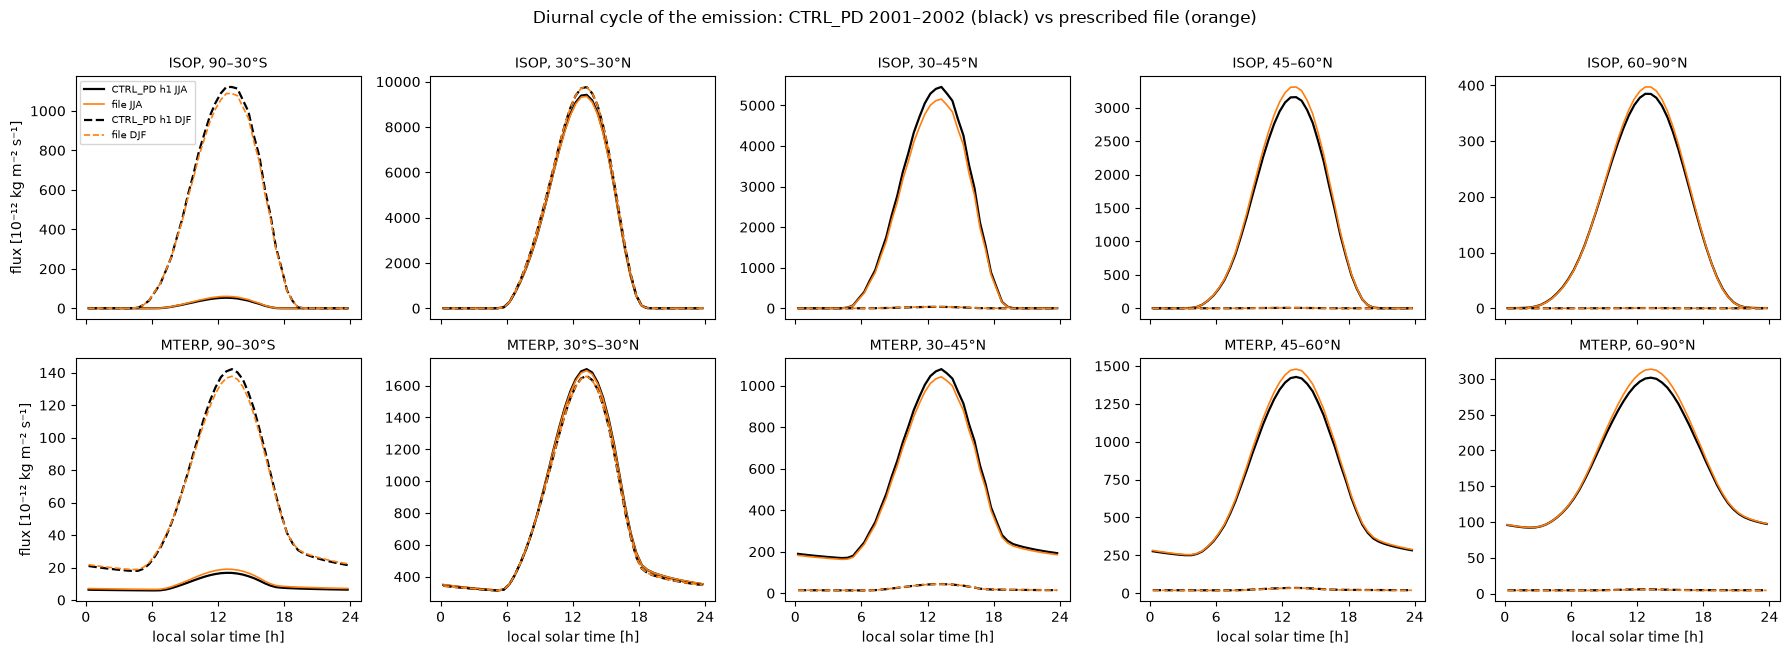

hour_of_max        night_share_pct        peak_over_mean      
source                          ctrl   clim            ctrl   clim           ctrl  clim
species band      season                                                               
ISOP    90–30°S   JJA          12.75  12.75            0.22   0.22           4.05  4.06
                  DJF          12.75  12.75            1.22   1.26           3.30  3.29
        30°S–30°N JJA          13.25  13.25            0.21   0.21           3.70  3.70
                  DJF          13.25  13.25            0.20   0.20           3.70  3.69
        30–45°N   JJA          13.25  13.25            1.36   1.33           3.31  3.31
                  DJF          12.75  12.75            0.17   0.17           4.15  4.16
        45–60°N   JJA          13.25  13.25            2.88   2.82           3.15  3.16
                  DJF          12.75  12.75            0.54   0.52           4.63  4.63
        60–90°N   JJA          12.75  13.25            7.14   6.91           2.75  2.78
                  DJF          12.25  12.25            2.47   2.58           5.04  4.94
MTERP   90–30°S   JJA          12.75  12.75           35.50  35.27           1.84  1.86
                  DJF          13.25  13.25           20.08  20.93           2.44  2.39
        30°S–30°N JJA          13.25  13.25           24.81  24.98           2.33  2.32
                  DJF          13.25  13.25           24.93  24.95           2.33  2.33
        30–45°N   JJA          13.25  13.25           21.96  21.90           2.30  2.30
                  DJF          13.25  13.25           33.39  33.64           1.97  1.96
        45–60°N   JJA          13.25  13.25           23.95  23.71           2.10  2.11
                  DJF          13.25  13.25           43.03  42.87           1.48  1.49
        60–90°N   JJA          13.25  13.25           31.77  31.26           1.70  1.73
                  DJF          12.75  12.75           47.54  47.70           1.19  1.18

In [10]:
SEASONS = {'DJF': [12, 1, 2], 'MAM': [3, 4, 5], 'JJA': [6, 7, 8], 'SON': [9, 10, 11]}
hours = np.arange(NSTEP) * 0.5 + 0.25
def composite(src, sp, months):
    sel = np.isin(MONTH[src], months)
    return D[src][f'{sp}_local'][sel].mean(0) / BANDW[:, None] * NSTEP   # band mean by local bin (kg m-2 s-1)

rows = []
fig, axes = plt.subplots(2, len(BANDS), figsize=(18, 6.5), sharex=True)
for r, sp in enumerate(('ISOP', 'MTERP')):
    for c, band in enumerate(BANDS):
        ax = axes[r, c]
        for season, ls in (('JJA', '-'), ('DJF', '--')):
            for src, col in (('ctrl', 'k'), ('clim', 'tab:orange')):
                y = composite(src, sp, SEASONS[season])[c]
                ax.plot(hours, y * 1e12, ls=ls, color=col, lw=1.6 if src == 'ctrl' else 1.2,
                        label=f"{'CTRL_PD h1' if src == 'ctrl' else 'file'} {season}")
                tot = y.sum()
                rows.append(dict(species=sp, band=band, season=season, source=src,
                                 hour_of_max=hours[y.argmax()] if tot > 0 else np.nan,
                                 night_share_pct=100 * y[(hours < 6) | (hours >= 18)].sum() / tot if tot > 0 else np.nan,
                                 peak_over_mean=y.max() / y.mean() if tot > 0 else np.nan))
        ax.set_title(f'{sp}, {band}', fontsize=10); ax.set_xticks(range(0, 25, 6))
        if r == 1: ax.set_xlabel('local solar time [h]')
        if c == 0: ax.set_ylabel('flux [10⁻¹² kg m⁻² s⁻¹]')
axes[0, 0].legend(fontsize=7)
fig.suptitle('Diurnal cycle of the emission: CTRL_PD 2001–2002 (black) vs prescribed file (orange)', y=1.0)
fig.tight_layout(); fig.savefig(OUT / 'figures' / 'H2b_diurnal_cycle.png', dpi=150, bbox_inches='tight'); plt.show()
t2b = pd.DataFrame(rows).pivot_table(index=['species', 'band', 'season'], columns='source',
                                    values=['hour_of_max', 'night_share_pct', 'peak_over_mean'], sort=False)
t2b.round(2).to_csv(OUT / 'tables' / 'H2b_diurnal_metrics.csv')
t2b.round(2)

### H2c. Lag test on the 30-min series
Correlation between the diurnal part (each day minus its daily mean) of the CTRL_PD 2001–2002 band-mean series and the file, at lags of −3 to +3 steps (positive lag = file later than CTRL_PD). A 30-min offset would put the maximum at ±1.

In [11]:
def diurnal_part(x):
    return (x - x.mean(-1, keepdims=True))
lags = range(-3, 4)
rows = []
for sp in ('ISOP', 'MTERP'):
    a = diurnal_part(D['ctrl'][f'{sp}_utc'])                     # (730, band, 48)
    b = diurnal_part(np.concatenate([D['clim'][f'{sp}_utc']] * 2))
    for c, band in enumerate(BANDS):
        sa, sb = a[:, c].ravel(), b[:, c].ravel()
        r = {L: np.corrcoef(sa[max(0, -L):len(sa) - max(0, L)], sb[max(0, L):len(sb) - max(0, -L)])[0, 1] for L in lags}
        rows.append(dict(species=sp, band=band, best_lag_steps=max(r, key=r.get), **{f'r(lag {L:+d})': r[L] for L in lags}))
t2c = pd.DataFrame(rows).set_index(['species', 'band'])
t2c.round(4).to_csv(OUT / 'tables' / 'H2c_lag_test.csv')
t2c.round(4)

best_lag_steps  r(lag -3)  r(lag -2)  r(lag -1)  r(lag +0)  r(lag +1)  r(lag +2)  r(lag +3)
species band                                                                                                  
ISOP    90–30°S                 0     0.6760     0.7953     0.8467     0.8862     0.8475     0.7969     0.6786
        30°S–30°N               0     0.7923     0.9048     0.9476     0.9857     0.9435     0.8965     0.7802
        30–45°N                 0     0.6590     0.8072     0.8693     0.9186     0.8682     0.8048     0.6552
        45–60°N                 0     0.4850     0.5957     0.6412     0.6903     0.6649     0.6425     0.5517
        60–90°N                 2     0.6124     0.6724     0.7057     0.7382     0.7413     0.7433     0.7166
MTERP   90–30°S                 0     0.6717     0.7760     0.8245     0.8564     0.8242     0.7754     0.6710
        30°S–30°N               0     0.8088     0.9099     0.9516     0.9838     0.9472     0.9013     0.7962
        30–45°N                 0     0.6656     0.8016     0.8620     0.9055     0.8608     0.7992     0.6622
        45–60°N                 0     0.4936     0.6000     0.6423     0.6790     0.6430     0.6010     0.4940
        60–90°N                 0     0.8018     0.8492     0.8737     0.8903     0.8824     0.8666     0.8275

### H2d. The 11 monthly species: how much do they matter for OH?
These files have no diurnal cycle (and CAM interpolates between mid-month values). Their possible effect on OH scales with their **OH reactivity** = emission (molecules cm⁻² s⁻¹) × k_OH. k_OH at 298 K, 1 atm from `pp_tropstrat_mam_oslo/chem_mech.in` (Arrhenius `A·exp(B/T)`; for the pressure-dependent and `usr_` reactions JPL-type values at 298 K, noted). Global and per band, annual means of the files.

In [12]:
T = 298.0
K_OH = {'ISOP': 2.54e-11 * np.exp(410 / T), 'MTERP': 1.2e-11 * np.exp(440 / T), 'BCARY': 2e-10,
        'C3H6': 2.9e-11,            # troe, high-pressure limit 3e-11 (JPL-type, 298 K, 1 atm)
        'BIGENE': 5.4e-11, 'CH3CHO': 4.63e-12 * np.exp(350 / T), 'CH2O': 5.5e-12 * np.exp(125 / T),
        'C2H4': 7.9e-12,            # troe (JPL-type, 298 K, 1 atm)
        'CH3OH': 2.9e-12 * np.exp(-345 / T), 'C2H5OH': 6.9e-12 * np.exp(-230 / T), 'CH3COOH': 7e-13,
        'CH3COCH3': 1.8e-13,        # usr_CH3COCH3_OH (JPL, 298 K)
        'HCOOH': 4e-13, 'HCN': 3e-14,  # troe, small (JPL-type)
        'CO': 2.4e-13,              # CO_OH_M + usr_CO_OH_b (JPL-type, 298 K, 1 atm)
        'C2H6': 7.66e-12 * np.exp(-1020 / T), 'C3H8': 8.7e-12 * np.exp(-615 / T), 'BIGALK': 3.5e-12,
        'TOLUENE': 1.7e-12 * np.exp(352 / T)}
rows = []
for sp in MOLAR_MASS:
    m = FM[f'{sp}_cam'].values / to_kg(sp)                       # annual mean as CAM reads it, molecules cm-2 s-1
    row = dict(species=sp, sampling='monthly' if sp in MONTHLY else '30 min', k_OH=K_OH[sp],
               Global=float((m * W[:, None]).sum() / (W.sum() * len(LON))) * K_OH[sp])
    for b, (lo, hi) in BANDS.items():
        sel = MASKS[list(BANDS).index(b)].astype(bool)
        row[b] = float((m[sel] * W[sel, None]).sum() / (W[sel].sum() * len(LON))) * K_OH[sp]
    rows.append(row)
t2d = pd.DataFrame(rows).set_index('species')
cols = ['Global'] + list(BANDS)
share = 100 * t2d[cols] / t2d[cols].sum()
share['sampling'] = t2d['sampling']
share.round(2).to_csv(OUT / 'tables' / 'H2d_OH_reactivity_share_pct.csv')
print('OH-reactivity share of the 11 monthly (flat) species [%]:')
print(share[share.sampling == 'monthly'][cols].sum().round(2).to_string())
share.sort_values('Global', ascending=False).round(2)

OH-reactivity share of the 11 monthly (flat) species [%]:
Global       0.59
90–30°S      0.78
30°S–30°N    0.52
30–45°N      1.60
45–60°N      1.80
60–90°N      2.05


,Global,90–30°S,30°S–30°N,30–45°N,45–60°N,60–90°N,sampling
species,,,,,,,
ISOP,87.52,88.62,88.25,80.07,70.19,60.19,30 min
MTERP,6.49,5.17,6.23,7.57,15.29,23.08,30 min
BCARY,1.52,1.05,1.48,1.94,2.61,2.58,30 min
C3H6,1.26,1.54,1.11,3.16,3.82,4.98,30 min
BIGENE,0.88,1.07,0.77,2.21,2.67,3.48,30 min
C2H4,0.86,0.96,0.78,2.18,2.08,1.95,30 min
CH3CHO,0.74,0.66,0.72,1.00,1.25,1.41,30 min
CH3OH,0.33,0.53,0.27,1.14,1.29,1.51,monthly
C2H5OH,0.15,0.13,0.15,0.20,0.25,0.29,monthly


### H2. Verdict
**H2 very unlikely (a for the files, b for how CAM samples them).**
- **30-min offset:** the file keeps CTRL_PD's stamps, and the CAM code samples it at the end of each step, i.e. the record CTRL_PD applied in that step (H2a, b: code reading, not confirmed in a run). The data agree: in every band and season the hour of maximum is the same as in CTRL_PD 2001–2002 (one exception: ISOP 60–90°N JJA, 12.75 vs 13.25 h, on a flat polar-day curve), the night share differs by ≤ 0.9 percentage points, and the lag test peaks at lag 0 (ISOP 60–90°N: flat, r = 0.738–0.743 for lags 0 to +2; MTERP in the same band peaks at 0) (H2b, H2c).
- **Monthly species without a diurnal cycle:** they make up 0.6 % of the BVOC OH reactivity globally, 1.6–2.0 % north of 30°N (H2d). Even a complete shift of their emission into the night could not change OH or the ISOP lifetime by +16 %.
- Not tested here: the CAM isoprene diurnal rescaling, which the fBVOC run skips. In CTRL_PD it acts only on the biomass-burning ISOP file (small), so skipping it is correct.

## H3. Lost emission–weather link
### H3a. How much day-to-day variability does the climatology remove?
Per band and month: **R** = Σ|E_day − C_day| / Σ C_day over cells and days (E = CTRL_PD daily mean 2001–2002, C = the file's daily mean for the same calendar day). R = 0.3 means that 30 % of the emission is moved between days by the weather in CTRL_PD and is spread evenly in the file. Monthly band means are also given (the monthly mismatch climatology vs 2001–2002).

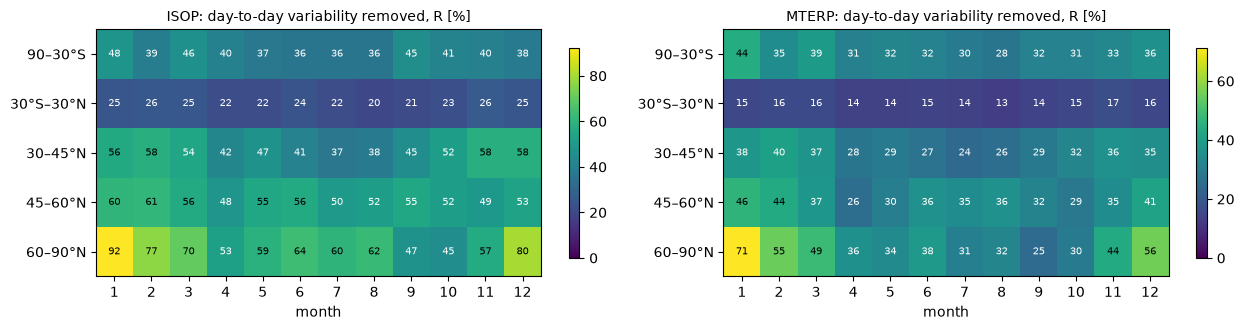

R_pct (flux-weighted)  R_pct JJA  R_pct DJF
species band                                                  
ISOP    90–30°S                     42.1       35.9       41.7
        30°S–30°N                   23.2       21.9       25.0
        30–45°N                     40.1       38.4       57.4
        45–60°N                     52.2       52.7       58.2
        60–90°N                     60.2       62.0       83.1
MTERP   90–30°S                     35.6       29.7       38.2
        30°S–30°N                   15.0       13.8       15.6
        30–45°N                     27.6       25.8       37.8
        45–60°N                     34.2       35.6       43.6
        60–90°N                     33.2       33.9       60.7

In [13]:
rows = []
for sp in ('ISOP', 'MTERP'):
    E = D['ctrl'][f'{sp}_daily'].astype(np.float64); C = np.concatenate([D['clim'][f'{sp}_daily']] * 2).astype(np.float64)
    for c, band in enumerate(BANDS):
        sel = MASKS[c].astype(bool)
        e, cc = E[:, sel] * W[sel, None], C[:, sel] * W[sel, None]
        for mo in range(1, 13):
            t = MONTH['ctrl'] == mo
            rows.append(dict(species=sp, band=band, month=mo,
                             R_pct=100 * np.abs(e[t] - cc[t]).sum() / cc[t].sum() if cc[t].sum() > 0 else np.nan,
                             monthly_mismatch_pct=100 * (e[t].sum() / cc[t].sum() - 1) if cc[t].sum() > 0 else np.nan,
                             band_flux=cc[t].sum() / (t.sum() * W[sel].sum() * len(LON))))
t3a = pd.DataFrame(rows)
t3a.to_csv(OUT / 'tables' / 'H3a_day_to_day_variability.csv', index=False, float_format='%.4g')
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, sp in zip(axes, ('ISOP', 'MTERP')):
    m = t3a[t3a.species == sp].pivot(index='band', columns='month', values='R_pct').loc[list(BANDS)]
    im = ax.imshow(m.values, cmap='viridis', vmin=0, aspect='auto')
    ax.set_yticks(range(len(BANDS)), m.index); ax.set_xticks(range(12), range(1, 13)); ax.set_xlabel('month')
    for (i, j), v in np.ndenumerate(m.values):
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7, color='w' if v < np.nanmax(m.values) * 0.6 else 'k')
    ax.set_title(f'{sp}: day-to-day variability removed, R [%]', fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.tight_layout(); fig.savefig(OUT / 'figures' / 'H3a_day_to_day_variability.png', dpi=150, bbox_inches='tight'); plt.show()
t3a.groupby(['species', 'band'], sort=False)[['month', 'R_pct', 'band_flux']].apply(
    lambda g: pd.Series({'R_pct (flux-weighted)': (g.R_pct * g.band_flux).sum() / g.band_flux.sum(),
                         'R_pct JJA': g[g.month.isin([6, 7, 8])].R_pct.mean(),
                         'R_pct DJF': g[g.month.isin([12, 1, 2])].R_pct.mean()})).round(1)

### H3b. Does the model response follow the variability that was removed?
If the lost weather link drives the artefact, the change in precursor lifetime (τ = column burden / emission) and in SOA should be largest in the band-months with the largest R. Per band and month (mean of 2001 and 2002), A in %: τ_ISOP, τ_MTERP, surface OH, SOA burden (`SOA_cb`). Spearman rank correlation with R over the band-months where the band emission is ≥ 5 % of that band's maximum month.

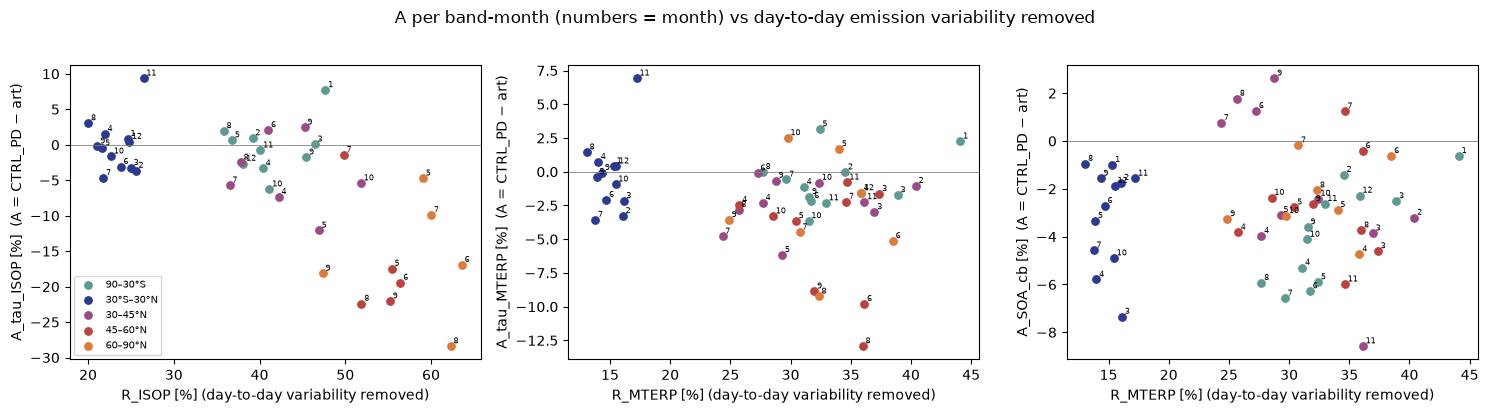

,x,y,n,spearman_rho,p_value
0,R_ISOP,A_tau_ISOP,39,-0.585,0.000
1,R_ISOP,A_OH_sfc,39,0.047,0.778
2,R_ISOP,A_SOA_cb,39,0.215,0.189
3,R_MTERP,A_tau_MTERP,50,-0.183,0.205
4,R_MTERP,A_OH_sfc,50,-0.004,0.980
5,R_MTERP,A_SOA_cb,50,-0.045,0.754


In [14]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
soa = {'ctrl': open_proc('CTRL_PD', 'SOA', 2001, 2014), 'art': open_proc('CTRL_PD_fBVOCctrlPD_test2yr', 'SOA', 2001, 2002)}
chem = {'ctrl': open_proc('CTRL_PD', 'CHEM', 2001, 2014), 'art': open_proc('CTRL_PD_fBVOCctrlPD_test2yr', 'CHEM', 2001, 2002)}
def monthly_band(ds, field):
    bm = bandmean(field)                                       # (time, band)
    return bm.groupby(ds['time'].dt.month).mean().transpose('month', 'band').to_pandas()  # (month, band)
resp = {}
for k in ('ctrl', 'art'):
    resp[k] = {'tau_ISOP': monthly_band(bv[k], bv[k]['cb_ISOP']) / monthly_band(bv[k], bv[k]['SFISOP']),
               'tau_MTERP': monthly_band(bv[k], bv[k]['cb_MTERP']) / monthly_band(bv[k], bv[k]['SFMTERP']),
               'OH_sfc': monthly_band(chem[k], chem[k]['OH'].isel(lev=-1)),
               'SOA_cb': monthly_band(soa[k], soa[k]['SOA_cb']),
               'SFISOP': monthly_band(bv[k], bv[k]['SFISOP']), 'SFMTERP': monthly_band(bv[k], bv[k]['SFMTERP'])}
A = {v: 100 * (1 - resp['art'][v] / resp['ctrl'][v]) for v in resp['ctrl']}   # interactive − prescribed
long = []
for band in BANDS:
    for mo in range(1, 13):
        g = t3a[(t3a.band == band) & (t3a.month == mo)].set_index('species')
        long.append(dict(band=band, month=mo, R_ISOP=g.loc['ISOP', 'R_pct'], R_MTERP=g.loc['MTERP', 'R_pct'],
                         flux_ISOP=g.loc['ISOP', 'band_flux'], flux_MTERP=g.loc['MTERP', 'band_flux'],
                         **{f'A_{v}': A[v].loc[mo, band] for v in A}))
L3 = pd.DataFrame(long)
L3['keep_ISOP'] = L3.groupby('band').flux_ISOP.transform(lambda s: s >= 0.05 * s.max())
L3['keep_MTERP'] = L3.groupby('band').flux_MTERP.transform(lambda s: s >= 0.05 * s.max())
L3.to_csv(OUT / 'tables' / 'H3b_band_month_response.csv', index=False, float_format='%.4g')
rows = []
for sp in ('ISOP', 'MTERP'):
    sub = L3[L3[f'keep_{sp}']]
    for y in (f'A_tau_{sp}', 'A_OH_sfc', 'A_SOA_cb'):
        rho, p = spearmanr(sub[f'R_{sp}'], sub[y])
        rows.append(dict(x=f'R_{sp}', y=y, n=len(sub), spearman_rho=rho, p_value=p))
t3b = pd.DataFrame(rows)
t3b.round(3).to_csv(OUT / 'tables' / 'H3b_spearman.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cmap = dict(zip(BANDS, ['#5D9A92', '#2C3990', '#9A4A84', '#BC423E', '#DE7A3A', '#EBC45C']))
for ax, (xv, yv, keep) in zip(axes, [('R_ISOP', 'A_tau_ISOP', 'keep_ISOP'), ('R_MTERP', 'A_tau_MTERP', 'keep_MTERP'),
                                     ('R_MTERP', 'A_SOA_cb', 'keep_MTERP')]):
    for band in BANDS:
        s = L3[(L3.band == band) & L3[keep]]
        ax.scatter(s[xv], s[yv], color=cmap[band], label=band, s=28)
        for _, row in s.iterrows():
            ax.annotate(int(row.month), (row[xv], row[yv]), fontsize=6, xytext=(2, 2), textcoords='offset points')
    ax.axhline(0, color='grey', lw=0.6); ax.set_xlabel(f'{xv} [%] (day-to-day variability removed)')
    ax.set_ylabel(f'{yv} [%]  (A = CTRL_PD − art)')
axes[0].legend(fontsize=7)
fig.suptitle('A per band-month (numbers = month) vs day-to-day emission variability removed', y=1.02)
fig.tight_layout(); fig.savefig(OUT / 'figures' / 'H3b_response_vs_variability.png', dpi=150, bbox_inches='tight'); plt.show()
t3b.round(3)

### H3c. Seasonal and latitudinal shape of A
Same band-month numbers as tables: if the artefact came from the boreal emissions (weather or timing), A in SOA north of 45°N should peak in summer, when those emissions peak.

In [15]:
for v in ('A_SFISOP', 'A_tau_ISOP', 'A_tau_MTERP', 'A_OH_sfc', 'A_SOA_cb'):
    print(f'--- {v} [%] (rows: band, columns: month; 2001–2002 mean)')
    print(L3.pivot(index='band', columns='month', values=v).loc[list(BANDS)].round(1).to_string())

--- A_SFISOP [%] (rows: band, columns: month; 2001–2002 mean)
month        1    2    3     4    5     6    7     8     9     10    11    12
band                                                                         
90–30°S     9.6  0.2 -0.3  -2.2 -8.3 -26.4 -7.5  -8.6  -1.8  -7.5  -0.6  -4.1
30°S–30°N   0.4 -0.3 -4.7  -1.6  0.4   1.1 -1.9   2.6  -0.6  -0.1   3.9  -0.2
30–45°N   -22.7 -3.5  1.2  -7.7 -1.6  10.8  3.8   4.0  11.3  15.0   3.6  -0.3
45–60°N     0.5 -6.9 -6.6  -6.4 -2.7  -1.6  1.3 -14.5 -12.5  -4.4   2.8  -6.7
60–90°N    30.0 -1.3 -4.9 -26.8  2.1  -4.0  3.3 -10.1 -12.6  -8.9 -12.1 -15.0
--- A_tau_ISOP [%] (rows: band, columns: month; 2001–2002 mean)
month        1     2     3     4     5     6    7     8     9     10   11    12
band                                                                           
90–30°S     7.7   0.9   0.1  -3.3   0.7   2.5 -0.4   1.9  -1.8  -6.3 -0.8  -2.6
30°S–30°N   0.9  -3.6  -3.3   1.5  -0.5  -3.1 -4.7   3.1  -0.2  -1.6  9.4   0.4
30–45°N 

### H3. Verdict
**H3 partly supported: it fits the longer precursor lifetime, but it does not explain the SOA increase.**
- **Size (a):** the climatology spreads evenly emission that CTRL_PD's weather moves between days. That is R = 23 % of ISOP in the tropics, 40–60 % in the northern extratropics, and 15–36 % for MTERP (H3a).
- **Precursor lifetime (a):** |A τ_ISOP| grows with R (Spearman ρ = −0.59, p < 0.001, 39 band-months): A = −10 to −20 % at 45–60°N for most months (longer lifetime in the prescribed run), ~0 in the tropics. For MTERP the relation is weak (ρ = −0.18, p = 0.2). **(b)** This fits the mechanism: CTRL_PD emits most on warm, sunny, high-OH days, while the file also emits on cool, cloudy days with low OH, so the precursor lives longer. The relation is partly latitude, though (R and Δτ both grow poleward), so it is not a clean test.
- **SOA (a):** A SOA is **not** related to R (ρ = +0.2 for ISOP, −0.05 for MTERP). Its seasonal shape is the opposite of a local emission effect: north of 30°N it is largest in size in Nov–Mar (A = −4 to −8 %) and ~0 or positive in Jun–Jul, when boreal emissions peak. In 90–30°S it is largest in austral winter (A = −6 %). The tropics, where most SOA forms, have A = −1 to −7 % although τ_ISOP and τ_MTERP barely change there.
- **(b)** So the SOA excess is made mainly in the tropics and carried to the winter hemisphere, or it lives longer there. It is not produced by the boreal emissions. A weather-link effect can still act in the tropics, but not through the precursor lifetime. It would have to come from **when** the precursors meet the oxidants: production ∝ mean([VOC]·[OH or O₃]) = product of the means + covariance. If CTRL_PD's high-emission days have lower OH (titration by isoprene), its covariance is negative, and removing it raises production with the same mean burdens, which is what the old 2001–2014 runs showed (§3 of `fbvoc_prescription_artefact.ipynb`). The monthly output cannot test this (c).

## H4. SOA budget: more production or less removal?
H1–H3 do not explain the +3 % SOA burden. Here the interstitial SOA budget (modes A1 + NA) of both runs, 2001–2002, from the h0 monthly means:

| Term | Fields | Sign in the files |
|---|---|---|
| **P** production (condensation of SOA_LV/SV) | `SOA_A1condTend + SOA_NAcondTend` | > 0 |
| coagulation (moves mass NA → A1) | `SOA_*coagTend` | sums to 0 |
| **cloud** transfer into droplets (net) | `SOA_A1_mixnuc1 + SOA_NA_mixnuc1` | < 0 (loss) |
| **wet** removal, interstitial | `SOA_A1SFWET + SOA_NASFWET` | < 0 (loss) |
| **dry** removal, interstitial | `SOA_A1DDF + SOA_NADDF` | > 0 (loss) |

Steady state: P + cloud + wet − dry ≈ 0. Lifetime **τ_P = SOA_cb / P** (days) = mean residence time of interstitial SOA. Exactly, ln(SOA_cb) = ln(P) + ln(τ_P), so the % change of the burden splits into a production part and a lifetime part. Cloud-borne SOA (`_OCW`) is not in the old-chain CTRL_PD output; 4e shows its size in the fBVOC run.

In [16]:
def gmean(ds, v):
    w = xr.DataArray(W, dims='lat', coords={'lat': ds['lat']})
    return float((ds[v].weighted(dpm).mean('time')).weighted(w).mean(('lat', 'lon')))
BUDGET = {'P': ('SOA_A1condTend', 'SOA_NAcondTend'), 'coag': ('SOA_A1coagTend', 'SOA_NAcoagTend'),
          'cloud': ('SOA_A1_mixnuc1', 'SOA_NA_mixnuc1'), 'wet': ('SOA_A1SFWET', 'SOA_NASFWET'),
          'dry': ('SOA_A1DDF', 'SOA_NADDF')}
for k in ('ctrl', 'art'):
    for name, (a1, na) in BUDGET.items():
        soa[k][name] = soa[k][a1] + soa[k][na]
rows = []
for k, alias in (('ctrl', 'CTRL_PD'), ('art', 'CTRL_PD_fBVOCctrlPD_test2yr')):
    g = {n: gmean(soa[k], n) for n in BUDGET}
    res = g['P'] + g['coag'] + g['cloud'] + g['wet'] - g['dry']
    rows.append(dict(run=alias, **{f'{n} [1e-12 kg m-2 s-1]': g[n] * 1e12 for n in BUDGET},
                     **{'residual / P [%]': 100 * res / g['P'], 'SOA_cb [mg m-2]': gmean(soa[k], 'SOA_cb') * 1e6,
                        'tau_P [days]': gmean(soa[k], 'SOA_cb') / g['P'] / 86400}))
t4a = pd.DataFrame(rows).set_index('run')
t4a.loc['A [%]'] = 100 * (1 - t4a.iloc[1] / t4a.iloc[0])   # interactive − prescribed, % of CTRL_PD
t4a.round(3).to_csv(OUT / 'tables' / 'H4a_global_budget.csv')
t4a.round(3)

,P [1e-12 kg m-2 s-1],coag [1e-12 kg m-2 s-1],cloud [1e-12 kg m-2 s-1],wet [1e-12 kg m-2 s-1],dry [1e-12 kg m-2 s-1],residual / P [%],SOA_cb [mg m-2],tau_P [days]
run,,,,,,,,
CTRL_PD,4.017,0.0,-0.884,-2.510,0.615,0.198,2.438,7.023
CTRL_PD_fBVOCctrlPD_test2yr,4.016,0.0,-0.893,-2.491,0.623,0.222,2.511,7.238
A [%],0.022,NaN,-0.983,0.765,-1.413,-11.811,-3.034,-3.057


### H4b. A by band and season [%]
Band means of the monthly means, then season means (2001–2002). τ_P = SOA_cb / P per band-season; `wet/P` etc. = share of production removed by each path (in percentage points of P, A = CTRL_PD − prescribed).

In [17]:
def season_band(ds, field):
    mb = monthly_band(ds, field)                               # (month, band), mean of the 2 years
    return pd.DataFrame({s: mb.loc[m].mean() for s, m in {**SEASONS, 'ANN': list(range(1, 13))}.items()}).T
SB = {}
for k in ('ctrl', 'art'):
    f = {v: season_band(soa[k], soa[k][v]) for v in ('SOA_cb', 'P', 'cloud', 'wet', 'dry', 'cb_SOA_LV', 'cb_SOA_SV')}
    f['tau_P'] = f['SOA_cb'] / f['P'] / 86400
    for path in ('cloud', 'wet', 'dry'):
        f[f'{path}/P'] = 100 * f[path].abs() / f['P']
    SB[k] = f
rows = []
for v in ('SOA_cb', 'P', 'tau_P', 'cb_SOA_LV', 'cb_SOA_SV', 'cloud', 'wet', 'dry', 'cloud/P', 'wet/P', 'dry/P'):
    d = (SB['ctrl'][v] - SB['art'][v]) if v.endswith('/P') else 100 * (1 - SB['art'][v] / SB['ctrl'][v])
    for season in d.index:
        rows.append(dict(variable=v, season=season, **d.loc[season].to_dict()))
t4b = pd.DataFrame(rows).set_index(['variable', 'season'])[list(BANDS)]
t4b.round(2).to_csv(OUT / 'tables' / 'H4b_A_budget_by_band_season.csv')
print('A = CTRL_PD − CTRL_PD_fBVOCctrlPD, %  (rows */P: difference in percentage points)')
t4b.round(1)

A = CTRL_PD − CTRL_PD_fBVOCctrlPD, %  (rows */P: difference in percentage points)


90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N
variable  season                                               
SOA_cb    DJF        -1.4       -1.5     -5.0     -6.3     -6.4
          MAM        -4.4       -5.5     -3.6     -3.6     -4.1
          JJA        -6.3       -2.7      1.3     -1.0     -1.0
          SON        -3.4       -2.7     -1.5     -3.4     -3.7
          ANN        -3.5       -3.1     -1.5     -2.8     -3.3
P         DJF         1.4        0.1     -0.4      3.1      6.7
          MAM        -0.5       -1.7     -0.7     -2.1     -2.4
          JJA        -2.9        0.5      4.2     -2.9     -0.9
          SON         0.1        0.7      8.0     -5.8     -5.1
          ANN         0.5       -0.1      4.1     -3.0     -1.4
tau_P     DJF        -2.9       -1.7     -4.6     -9.8    -14.1
          MAM        -3.8       -3.7     -2.8     -1.5     -1.7
          JJA        -3.3       -3.2     -3.0      1.8     -0.0
          SON        -3.5       -3.5    -10.4      2.3      1.3
          ANN        -4.0       -3.0     -5.8      0.2     -1.8
cb_SOA_LV DJF        -0.2       -4.4     -0.5     -2.9     -9.0
          MAM        -0.1       -4.6     -4.5     -9.2     -5.2
          JJA         0.1       -3.6     -3.4    -11.2     -5.2
          SON        -0.4       -4.4     -0.4    -12.9     -5.1
          ANN        -0.2       -4.3     -2.7    -10.9     -5.2
cb_SOA_SV DJF        -0.5       -3.2      0.5     12.2     21.2
          MAM        -0.1       -3.7     -4.7     -4.2     -0.6
          JJA         0.3       -3.2     -4.4     -6.0     -0.9
          SON        -0.7       -3.2     -1.4     -4.3      0.2
          ANN        -0.4       -3.3     -3.5     -4.2      0.5
cloud     DJF         1.9       -0.8     -1.1      0.8      3.4
          MAM         0.2       -4.2     -1.3     -2.9     -0.4
          JJA        -2.1       -2.2      4.7     -0.6      1.0
          SON         2.0       -1.0      2.1      0.5     -4.1
          ANN         1.2       -2.0      2.0     -0.6     -0.1
wet       DJF         2.6        0.9     -2.2     -3.5     -3.4
          MAM         0.5       -0.8      1.8      2.8      5.2
          JJA        -2.4        0.7      5.6      2.0      4.9
          SON        -0.7        1.5      7.2     -1.0     -4.6
          ANN         0.6        0.6      5.0      1.7      4.1
dry       DJF        -0.4       -1.3     -3.9    -10.7    -17.2
          MAM        -2.2       -3.6     -3.0     -5.4     -7.3
          JJA        -5.5       -0.2      0.8     -7.0     -6.6
          SON        -1.8       -0.0      2.8     -8.1    -10.0
          ANN        -1.5       -1.2      0.5     -7.1     -7.5
cloud/P   DJF         0.3       -0.2     -1.7     -3.8     -8.3
          MAM         0.6       -0.4     -0.5     -0.5      2.9
          JJA         1.1       -0.4      0.1      0.9      2.0
          SON         2.3       -0.3     -2.8      5.3      1.9
          ANN         0.5       -0.3     -0.9      1.2      1.6
wet/P     DJF         0.3        0.5     -2.4     -1.1     -1.3
          MAM         0.5        0.6      1.5      0.8      1.2
          JJA         0.4        0.1      0.9      1.5      1.8
          SON        -0.3        0.5     -0.5      0.9      0.1
          ANN         0.0        0.4      0.6      1.3      1.5
dry/P     DJF        -0.3       -0.2     -1.6     -4.3     -8.7
          MAM        -0.3       -0.3     -0.7     -0.7     -1.3
          JJA        -0.7       -0.1     -0.9     -0.8     -1.1
          SON        -0.4       -0.1     -1.7     -0.6     -1.4
          ANN        -0.4       -0.2     -1.0     -0.8     -1.3

### H4c. Production or lifetime? Δln(SOA_cb) = Δln(P) + Δln(τ_P)
In % (100 × Δln, Δ = CTRL_PD − prescribed as for A; close to the % change for small changes). The larger of the two terms is the one that makes the burden change.

In [18]:
rows = []
for season in ('ANN', 'DJF', 'JJA'):
    for band in BANDS:
        dB, dP, dT = (100 * np.log(SB['ctrl'][v].loc[season, band] / SB['art'][v].loc[season, band]) for v in ('SOA_cb', 'P', 'tau_P'))   # ln(ctrl/art): interactive − prescribed
        rows.append(dict(season=season, band=band, dln_SOA_cb=dB, dln_P=dP, dln_tau_P=dT,
                         dominant='lifetime' if abs(dT) > abs(dP) else 'production'))
t4c = pd.DataFrame(rows).set_index(['season', 'band'])
t4c.round(2).to_csv(OUT / 'tables' / 'H4c_production_vs_lifetime.csv')
t4c.round(2)

dln_SOA_cb  dln_P  dln_tau_P    dominant
season band                                               
ANN    90–30°S         -3.46   0.51      -3.96    lifetime
       30°S–30°N       -3.07  -0.08      -2.99    lifetime
       30–45°N         -1.44   4.20      -5.65    lifetime
       45–60°N         -2.79  -3.00       0.21  production
       60–90°N         -3.20  -1.42      -1.78    lifetime
DJF    90–30°S         -1.42   1.43      -2.85    lifetime
       30°S–30°N       -1.53   0.14      -1.67    lifetime
       30–45°N         -4.84  -0.36      -4.47    lifetime
       45–60°N         -6.11   3.20      -9.31    lifetime
       60–90°N         -6.23   6.95     -13.17    lifetime
JJA    90–30°S         -6.07  -2.82      -3.25    lifetime
       30°S–30°N       -2.65   0.47      -3.12    lifetime
       30–45°N          1.28   4.27      -2.98  production
       45–60°N         -1.00  -2.82       1.82  production
       60–90°N         -0.98  -0.93      -0.04  production

### H4d. Zonal means of A [%]
Zonal mean of each run (2001–2002, by season), then the % change. Latitudes with very small P (polar night) are masked (P < 2 % of the global-maximum zonal P of that season).

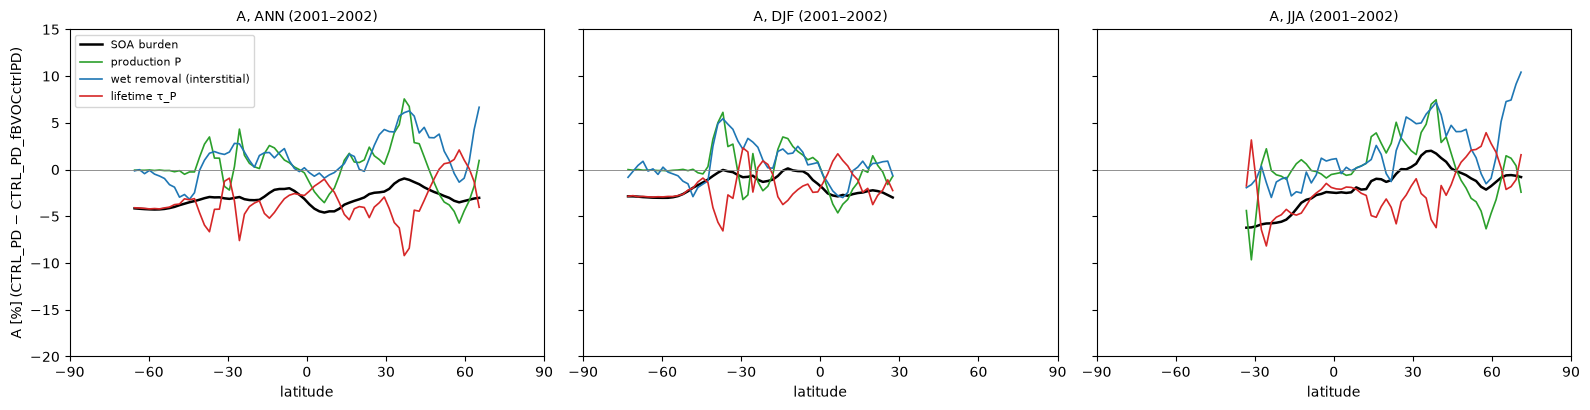

In [19]:
def zonal(ds, v, months):
    sel = ds[v].isel(time=ds['time'].dt.month.isin(months).values)
    return sel.mean(('time', 'lon'))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (season, months) in zip(axes, [('ANN', list(range(1, 13))), ('DJF', SEASONS['DJF']), ('JJA', SEASONS['JJA'])]):
    z = {k: {v: zonal(soa[k], v, months) for v in ('SOA_cb', 'P', 'wet')} for k in ('ctrl', 'art')}
    for k in z:
        z[k]['tau_P'] = z[k]['SOA_cb'] / z[k]['P']
    ok = z['ctrl']['P'] > 0.02 * z['ctrl']['P'].max()
    for v, col in (('SOA_cb', 'k'), ('P', 'tab:green'), ('wet', 'tab:blue'), ('tau_P', 'tab:red')):
        a = 100 * (1 - z['art'][v] / z['ctrl'][v])   # A = interactive − prescribed
        ax.plot(LAT, a.where(ok), color=col, lw=1.8 if v == 'SOA_cb' else 1.2,
                label={'SOA_cb': 'SOA burden', 'P': 'production P', 'wet': 'wet removal (interstitial)', 'tau_P': 'lifetime τ_P'}[v])
    ax.axhline(0, color='grey', lw=0.6); ax.set_title(f'A, {season} (2001–2002)', fontsize=10); ax.set_xlabel('latitude')
    ax.set_xlim(-90, 90); ax.set_xticks(range(-90, 91, 30))
axes[0].set_ylabel('A [%] (CTRL_PD − CTRL_PD_fBVOCctrlPD)'); axes[0].legend(fontsize=8)
for ax in axes:
    ax.set_ylim(-20, 15)
fig.tight_layout(); fig.savefig(OUT / 'figures' / 'H4_soa_budget_zonal.png', dpi=150, bbox_inches='tight'); plt.show()

### H4e. How much SOA leaves through clouds? (fBVOC run only)
The interstitial budget above sees the cloud path only as the transfer into droplets (`mixnuc1`). The fBVOC run also has the removal of cloud-borne SOA (`SOA_*_OCWSFWET`, `_OCWDDF`) and the model column burdens (`cb_SOA_*`). This shows how much of the budget the old-chain CTRL_PD output cannot see.

In [20]:
a = soa['art']
g = {v: gmean(a, v) for v in ('SOA_A1_OCWSFWET', 'SOA_NA_OCWSFWET', 'SOA_A1_OCWDDF', 'SOA_NA_OCWDDF',
                              'cb_SOA_A1', 'cb_SOA_NA', 'cb_SOA_A1_OCW', 'cb_SOA_NA_OCW', 'SOA_cb')}
gb = {n: gmean(a, n) for n in BUDGET}
ocw_rm = abs(g['SOA_A1_OCWSFWET'] + g['SOA_NA_OCWSFWET']) + g['SOA_A1_OCWDDF'] + g['SOA_NA_OCWDDF']
int_rm = abs(gb['wet']) + gb['dry']
print(f"removal: interstitial wet+dry {int_rm*1e12:.3f}, cloud-borne wet+dry {ocw_rm*1e12:.3f} (1e-12 kg m-2 s-1)"
      f" -> cloud-borne share {100*ocw_rm/(ocw_rm+int_rm):.1f} %")
print(f"transfer into droplets (-mixnuc1) {-gb['cloud']*1e12:.3f} vs cloud-borne removal {ocw_rm*1e12:.3f}")
cb_int, cb_ocw = g['cb_SOA_A1'] + g['cb_SOA_NA'], g['cb_SOA_A1_OCW'] + g['cb_SOA_NA_OCW']
print(f"burden: interstitial model cb {cb_int*1e6:.3f} mg m-2 (offline SOA_cb {g['SOA_cb']*1e6:.3f}), cloud-borne {cb_ocw*1e6:.3f} mg m-2"
      f" -> cloud-borne share {100*cb_ocw/(cb_ocw+cb_int):.1f} %")

removal: interstitial wet+dry 3.114, cloud-borne wet+dry 0.903 (1e-12 kg m-2 s-1) -> cloud-borne share 22.5 %
transfer into droplets (-mixnuc1) 0.893 vs cloud-borne removal 0.903
burden: interstitial model cb 2.511 mg m-2 (offline SOA_cb 2.511), cloud-borne 0.025 mg m-2 -> cloud-borne share 1.0 %


### H4f. Where in the column? Vertical profiles of A
Production is unchanged but SOA stays longer. One possible reason (b): SOA that forms **higher** in the troposphere is washed out more slowly. If the precursors live longer (H3), they are oxidised higher up. Test: band-mean profiles of A (%) for the SOA gas products (`SOA_LV`, `SOA_SV`, where condensation happens) and the SOA aerosol (`SOA_A1 + SOA_NA`), annual mean 2001–2002, on the model levels (`lev`, ≈ hPa).

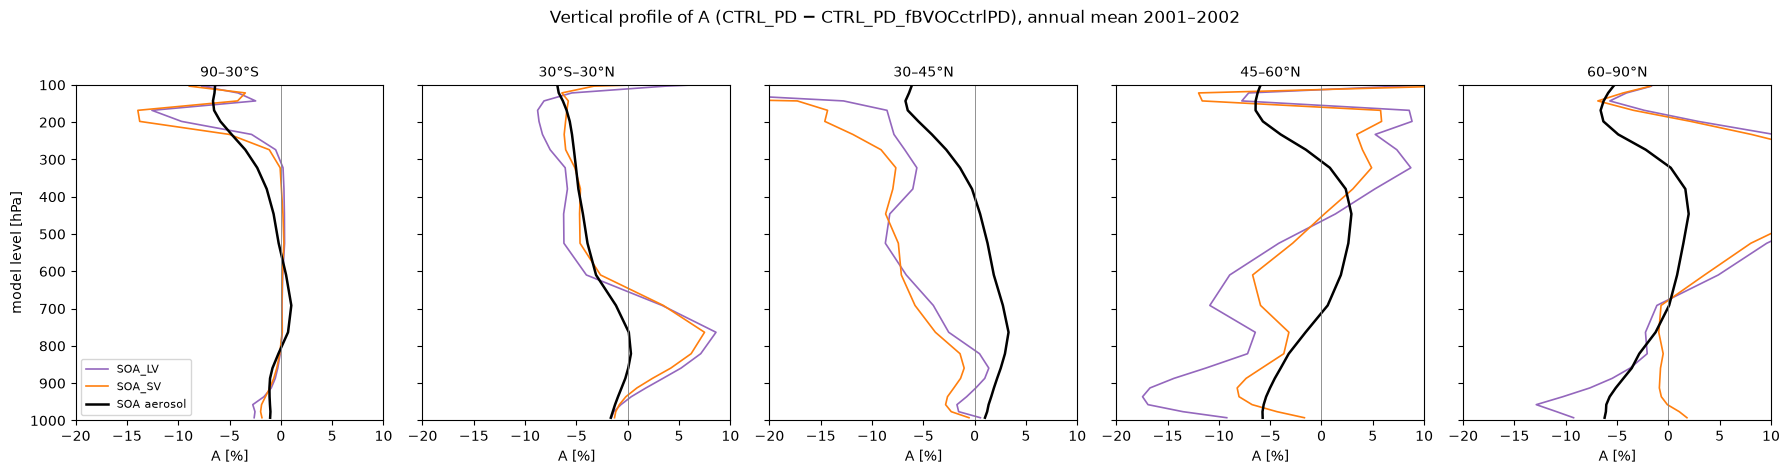

band                       90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N
variable    layer                                                       
SOA_LV      below 800 hPa     -1.0        0.4     -0.2    -12.5     -8.6
            800–400 hPa        0.2       -3.9     -6.9     -6.3      1.1
            400–100 hPa       -0.6       -7.5     -6.7      6.8     16.3
SOA_SV      below 800 hPa     -1.1        0.4     -1.6     -4.3      0.5
            800–400 hPa        0.2       -2.1     -6.8     -3.9      0.9
            400–100 hPa       -1.7       -5.8    -10.0      4.0     14.8
SOA aerosol below 800 hPa     -0.9       -0.8      1.8     -5.0     -5.1
            800–400 hPa        0.1       -2.3      1.9      1.4      1.0
            400–100 hPa       -5.5       -5.8     -5.0     -4.6     -4.8

In [21]:
fig, axes = plt.subplots(1, len(BANDS), figsize=(18, 4.6), sharey=True)
rows = []
for ax, (band, (lo, hi)) in zip(axes, BANDS.items()):
    prof = {}
    for k in ('ctrl', 'art'):
        ds = soa[k]
        w = xr.DataArray(W, dims='lat', coords={'lat': ds['lat']}).sel(lat=slice(lo, hi))
        sel = lambda v: ds[v].sel(lat=slice(lo, hi)).weighted(dpm).mean('time').weighted(w).mean(('lat', 'lon'))
        prof[k] = {'SOA_LV': sel('SOA_LV'), 'SOA_SV': sel('SOA_SV'), 'SOA aerosol': sel('SOA_A1') + sel('SOA_NA')}
    lev = soa['ctrl']['lev'].values
    for v, col in (('SOA_LV', 'tab:purple'), ('SOA_SV', 'tab:orange'), ('SOA aerosol', 'k')):
        a = 100 * (1 - prof['art'][v] / prof['ctrl'][v])   # A = interactive − prescribed
        ax.plot(a, lev, color=col, label=v, lw=1.8 if v == 'SOA aerosol' else 1.2)
        for lo_p, hi_p, name in ((800, 1100, 'below 800 hPa'), (400, 800, '800–400 hPa'), (100, 400, '400–100 hPa')):
            m = (lev >= lo_p) & (lev < hi_p)
            # mass-weighted layer change: ratio of layer sums (levels ~ equal-pressure weights, approximate)
            rows.append(dict(band=band, variable=v, layer=name,
                             A_pct=100 * (1 - float(prof['art'][v][m].sum()) / float(prof['ctrl'][v][m].sum()))))
    ax.axvline(0, color='grey', lw=0.6); ax.set_title(band, fontsize=10); ax.set_xlabel('A [%]'); ax.set_xlim(-20, 10)
axes[0].set_ylim(1000, 100); axes[0].set_ylabel('model level [hPa]'); axes[0].legend(fontsize=8)
fig.suptitle('Vertical profile of A (CTRL_PD − CTRL_PD_fBVOCctrlPD), annual mean 2001–2002', y=1.02)
fig.tight_layout(); fig.savefig(OUT / 'figures' / 'H4f_vertical_profiles.png', dpi=150, bbox_inches='tight'); plt.show()
t4f = pd.DataFrame(rows).pivot_table(index=['variable', 'layer'], columns='band', values='A_pct', sort=False)[list(BANDS)]
t4f.round(2).to_csv(OUT / 'tables' / 'H4f_A_by_layer.csv')
t4f.round(1)

### H4. Verdict
**Lifetime, not production (a); the extra SOA sits in the upper troposphere (a); likely cause: SOA forms higher up (b).**
- **Global (4a):** production P is unchanged (A = +0.02 %), yet the prescribed run has a 3.0 % larger burden (A = −3.0 %): its lifetime τ_P is 7.24 instead of 7.02 days (A = −3.1 %). The budget closes to 0.2 % of P in both runs. With equal production, the total removal is equal too, so the same SOA mass is removed more slowly; in the prescribed run wet removal −0.8 %, dry +1.4 %, transfer into cloud droplets +1.0 % (A = +0.8, −1.4, −1.0 %).
- **By band (4b, 4c; changes in the prescribed run, = −A):** the lifetime dominates the burden change in 4 of 5 bands, annual mean (τ_P +3–4 % in the tropics and the Southern Hemisphere, +6 % at 30–45°N). In NH winter τ_P is +9 to +14 % north of 45°N. The exception is 45–60°N annual and NH summer, where production changes (+3 %) follow the local emission difference of the 2001–2002 climatology (H1d).
- **Vertical (4f; prescribed run, = −A):** the SOA aerosol increase is concentrated at **400–100 hPa** in every band (+4.6 to +5.8 %); near the surface it is ≈ 0 (±2 %), except +5 % north of 45°N, where dry deposition also rises (+7 %). In the tropics the SOA gas products (`SOA_LV`, `SOA_SV`), where condensation happens, rise at 400–100 hPa (+7.5 %, +5.8 %) but not below 800 hPa (−0.4 %). So in the tropics SOA is **produced higher up** with the same total production.
- **Cloud path (4e):** in the fBVOC run 22 % of SOA removal goes through cloud-borne SOA, but the cloud-borne burden is only 1 % of the total; the interstitial budget is therefore the right one for the burden. The old-chain CTRL_PD lacks the cloud-borne fields, so that part of A cannot be computed.
- **Proposed mechanism (b, to be tested by the replay run):** SOA formed in the upper troposphere is washed out more slowly and spreads to all latitudes, which gives the +3 % burden, largest in winter when local removal or production is weak. Why the climatology would shift tropical SOA formation upward: in CTRL_PD, emissions peak on clear, hot days; the climatology also emits on convective, cloudy days, when deep convection lifts the precursors before they are oxidised (b). This is the weather link of H3 acting through convection, not through the local oxidant level.

## H5. Replay run `CTRL_PD_fBVOCctrlPD_HR`: climatology or prescription path?
`CTRL_PD_fBVOCctrlPD_HR` = `CTRL_PD_fBVOCctrlPD` with CTRL_PD's **actual** emissions of each year (2000, 2001, 2002; files `ems_<CTRL_PD>_Y-Y_*.nc`, swapped between 1-year jobs by `replay_prerun.sh`, script `cases-scripts/14d-…`). The weather and year-to-year variability that the climatology removes is back by construction; only the 11 monthly species still lack a diurnal cycle (0.6 % of OH reactivity, H2d).

| Key | Contrast | Meaning |
|---|---|---|
| **R** | CTRL_PD − CTRL_PD_fBVOCctrlPD_HR | prescription path alone (same emissions step by step) |
| **A − R** | CTRL_PD_fBVOCctrlPD_HR − CTRL_PD_fBVOCctrlPD | climatology alone |

Verdict rule (SOA_cb, global, as in the artefact test): |R| < 0.75 % → the artefact comes from the **climatology**; R < −1.5 % → from the **prescription path**; in between → both.
**H5a** first checks that the run really received CTRL_PD's flux at every 30-min step (h1 `SFISOP`, `SFMTERP`).

In [22]:
REPLAY = 'CTRL_PD_fBVOCctrlPD_HR'
HR_CASES = sorted(Path('/cluster/work/users/adelez/archive').glob('NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_HR_f19_f19-*'))
HAVE_REPLAY = (PROC / f'{REPLAY}_atm_SOA_2001-2002.nc').exists()
print('replay case(s) in the work archive:', [c.name for c in HR_CASES], '| processed files:', HAVE_REPLAY)

# H5a: step-by-step flux check on sample days (replay h1 vs CTRL_PD h1, same time stamps, and shifted by one step)
rows = []
if HR_CASES:
    hr_hist = HR_CASES[-1] / 'atm/hist'
    for day in ('2000-07-01', '2001-01-15', '2001-07-01', '2002-07-01', '2002-12-31'):
        f_hr = hr_hist / f'{HR_CASES[-1].name}.cam.h1.{day}-00000.nc'
        if not f_hr.exists():
            continue
        with nc.Dataset(f_hr) as a, nc.Dataset(H1_DIR / f'{CTRL}.cam.h1.{day}-00000.nc') as b:
            for v in ('SFISOP', 'SFMTERP'):
                x, y = a[v][:].data.astype(np.float64), b[v][:].data.astype(np.float64)
                big = y > 0.01 * y.max()
                rel = lambda p, q: float(np.max(np.abs(p - q)[big[:len(p)]] / q[big[:len(p)]])) if big[:len(p)].any() else np.nan
                rows.append(dict(day=day, field=v, max_rel_diff_same_step=rel(x, y),
                                 max_rel_diff_shift_plus1=float(np.median(np.abs(x[1:] - y[:-1])[big[1:]] / y[:-1][big[1:]])),
                                 note='median for the shifted comparison'))
t5a = pd.DataFrame(rows)
if len(t5a):
    t5a.to_csv(OUT / 'tables' / 'H5a_h1_flux_check.csv', index=False)
    print(t5a.round(8).to_string(index=False))
else:
    print('No replay h1 files yet.')

replay case(s) in the work archive: ['NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_HR_f19_f19-20261029'] | processed files: True
       day   field  max_rel_diff_same_step  max_rel_diff_shift_plus1                              note
2000-07-01  SFISOP                0.000475                  0.076764 median for the shifted comparison
2000-07-01 SFMTERP                0.000475                  0.032050 median for the shifted comparison
2001-01-15  SFISOP                0.000475                  0.080074 median for the shifted comparison
2001-01-15 SFMTERP                0.000475                  0.031148 median for the shifted comparison
2001-07-01  SFISOP                0.000475                  0.081577 median for the shifted comparison
2001-07-01 SFMTERP                0.000475                  0.032017 median for the shifted comparison
2002-07-01  SFISOP                0.000475                  0.071945 median for the shifted comparison
2002-07-01 SFMTERP                0.000475  

In [23]:
if HAVE_REPLAY:
    hr = {'SOA': open_proc(REPLAY, 'SOA', 2001, 2002), 'BVOC': open_proc(REPLAY, 'BVOC', 2001, 2002),
          'CHEM': open_proc(REPLAY, 'CHEM', 2001, 2002)}
    for name, (a1, na) in BUDGET.items():
        hr['SOA'][name] = hr['SOA'][a1] + hr['SOA'][na]
    runs = {'ctrl': (soa['ctrl'], bv['ctrl'], chem['ctrl']), 'art': (soa['art'], bv['art'], chem['art']),
            'hr': (hr['SOA'], hr['BVOC'], hr['CHEM'])}
    F5 = {}
    for k, (s_, b_, c_) in runs.items():
        f = {'SOA_cb': season_band(s_, s_['SOA_cb']), 'P': season_band(s_, s_['P'])}
        f['tau_P'] = f['SOA_cb'] / f['P']
        f['tau_ISOP'] = season_band(b_, b_['cb_ISOP']) / season_band(b_, b_['SFISOP'])
        f['tau_MTERP'] = season_band(b_, b_['cb_MTERP']) / season_band(b_, b_['SFMTERP'])
        f['OH_sfc'] = season_band(c_, c_['OH'].isel(lev=-1))
        f['SFISOP'] = season_band(b_, b_['SFISOP'])
        F5[k] = f
    rows = []
    for v in F5['ctrl']:
        for key, (c1, c2) in {'A': ('art', 'ctrl'), 'R': ('hr', 'ctrl'), 'A−R': ('art', 'hr')}.items():
            d = 100 * (1 - F5[c1][v] / F5[c2][v])   # interactive − prescribed (A, R), replay − climatology (A−R)
            for season in ('ANN', 'DJF', 'JJA'):
                rows.append(dict(variable=v, contrast=key, season=season, **d.loc[season].to_dict()))
    t5b = pd.DataFrame(rows).set_index(['variable', 'contrast', 'season'])[list(BANDS)]
    t5b.round(2).to_csv(OUT / 'tables' / 'H5b_replay_contrasts.csv')
    g = {k: gmean(s_, 'SOA_cb') for k, (s_, _, _) in runs.items()}
    R, A_ = 100 * (1 - g['hr'] / g['ctrl']), 100 * (1 - g['art'] / g['ctrl'])
    verdict = ('the artefact comes from the CLIMATOLOGY' if abs(R) < 0.75 else
               'the artefact comes from the PRESCRIPTION PATH' if R < -1.5 else 'MIXED: both contribute')
    print(f'SOA_cb global: A = {A_:+.2f} %, R = {R:+.2f} %, A − R ≈ {A_ - R:+.2f} %  ->  {verdict}')
    (OUT / 'tables' / 'H5_verdict.txt').write_text(f'SOA_cb global: A = {A_:+.2f} %, R = {R:+.2f} % -> {verdict}\n')
    display(t5b.round(1))
else:
    print(f'{REPLAY} not postprocessed yet (cases-scripts/run_when_done/run_replay_when_done.sh reruns this notebook when it is).')

SOA_cb global: A = -3.03 %, R = -0.49 %, A − R ≈ -2.55 %  ->  the artefact comes from the CLIMATOLOGY


90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N
variable contrast season                                               
SOA_cb   A        ANN        -3.5       -3.1     -1.5     -2.8     -3.3
                  DJF        -1.4       -1.5     -5.0     -6.3     -6.4
                  JJA        -6.3       -2.7      1.3     -1.0     -1.0
         R        ANN        -0.4       -0.6     -0.2     -0.1     -0.3
                  DJF         0.0       -0.4     -0.4     -0.6     -0.6
...                           ...        ...      ...      ...      ...
SFISOP   R        DJF         0.0        0.0      0.0      0.0      0.0
                  JJA         0.0        0.0      0.0      0.0      0.0
         A−R      ANN         0.7       -0.1      5.8     -5.0     -2.9
                  DJF         2.8       -0.1     -7.3     -5.2      3.2
                  JJA       -12.5        0.7      5.6     -4.5     -2.2

[63 rows x 5 columns]

### H5. Verdict
**The artefact comes from the climatology, not from the prescription path (a).** Global SOA burden, 2001–2002: A = **−3.03 %**, R = **−0.49 %**, A − R ≈ **−2.55 %** (rule: |R| < 0.75 % → climatology).

**H5a, delivery check (a):** at every tested 30-min step the replay run received CTRL_PD's `SFISOP` and `SFMTERP` to within 4.7 × 10⁻⁴ (relative); shifted by one step the difference is 3–8 %, so the timing is right. The small offset is a uniform −0.05 % in the replay flux (`SFISOP` R = +0.05 % in H5b), likely from file precision (c).

**H5b, by band (annual means, %):**

| Variable | Contrast | 90–30°S | 30°S–30°N | 30–45°N | 45–60°N | 60–90°N |
|---|---|---|---|---|---|---|
| SOA burden | A | −3.5 | −3.1 | −1.5 | −2.8 | −3.3 |
| | **R** | **−0.4** | **−0.6** | **−0.2** | **−0.1** | **−0.3** |
| SOA production P | R | 0.0 | +0.1 | 0.0 | 0.0 | 0.0 |
| SOA lifetime τ_P | A | −4.0 | −3.0 | −5.8 | +0.2 | −1.8 |
| | R | −0.4 | −0.6 | −0.2 | −0.2 | −0.3 |
| ISOP lifetime | A | +1.4 | +0.4 | −2.8 | −13.0 | −18.5 |
| | R | −0.2 | −0.4 | −1.2 | −0.8 | −0.8 |

- With the real year-by-year emissions, the SOA burden, SOA lifetime and isoprene lifetime return to CTRL_PD's values within 0.6 % (1.2 % for isoprene lifetime at 30–45°N) in every band **(a)**. The longer high-latitude isoprene lifetime of the prescribed run in H3 (A = −13 to −19 %) disappears **(a)**: it was caused by the climatology.
- What "climatology" includes: A − R mixes (i) the lost link between emissions and each day's weather and (ii) the fact that the 2001–2014 mean is not the 2001–2002 emission (`SFISOP` A: +5.9 % at 30–45°N, −5.0 % at 45–60°N). This test does not separate (i) from (ii) **(b)**. Since global SOA production is unchanged (H4) and the effect is in the lifetime, (i) is the more likely driver **(b)**.
- R = −0.49 % is small but has the same sign in all bands. With 2 years and no ensemble, it is not known whether it is noise **(c)**.

**Consequence:** a fixed-BVOC run fed by a climatology carries a +2.5 to +3 % SOA bias by construction. Two ways around it: compare with a matched fixed-BVOC baseline that has the same bias (e.g. LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD), or prescribe the source run's actual emissions year by year (replay design, R ≈ −0.5 %).

## Summary
| Hypothesis | Verdict | Key number |
|---|---|---|
| H1 missing species | **rejected (a)** | 19/19 species; totals within 0.01 % (2001–2014); same coupler fields except the VOC fluxes |
| H2 diurnal timing | **rejected (a, b)** | same local hour of maximum and night share; lag 0; flat monthly species = 0.6 % of OH reactivity |
| H3 lost weather link | **real for the precursors (a); for SOA only indirectly (b)** | prescribed run τ_ISOP +10–28 % at 45–90°N (A = −10 to −28 %), ρ(A, R) = −0.59; SOA not correlated with R |
| H4 SOA budget | **lifetime, not production (a)** | A: P +0.02 %, τ_P −3.1 %; the prescribed run has extra SOA at 400–100 hPa (+5 %) and tropical SOA gases +7.5 % aloft |
| H5 replay (actual year-by-year emissions) | **the climatology is the cause, not the prescription path (a)** | SOA burden: A −3.03 %, R −0.49 %, A − R −2.55 % (global); |R| ≤ 0.6 % in every band; ISOP lifetime at 45–90°N back to CTRL_PD (|R| ≤ 0.8 %) |

**Explanation:** the cause is the climatology (H5, **(a)**); the mechanism below is **(b)**. Prescribing a climatology changes **where** SOA forms, not how much. In the tropics more SOA forms in the upper troposphere, where it lives longer, and it spreads to all latitudes. The likely reason is the lost weather link (emissions no longer avoid convective days), which lifts precursors before oxidation.

**Replay test (done, H5):** `CTRL_PD_fBVOCctrlPD_HR` prescribes CTRL_PD's *actual* emissions of each year (2000–2002) and stays within +0.5 % of CTRL_PD's SOA. So the +3 % comes from the climatology **(a)**, and the prescription path itself adds at most ~0.5 % (c: may be noise).
- Fix options: the matched baseline (LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD), where the climatology bias is assumed to cancel **(b)**, or replay-type emissions (each year's actual emissions of the source run).
- Its 30-min `SFISOP`/`SFMTERP` also confirm in a run that the prescribed flux arrives at the right step (H5a).

## Synthesis figure: what raises SOA in the fixed-BVOC run?
One figure for the chain found in H1–H4 (A = `CTRL_PD − CTRL_PD_fBVOCctrlPD`, 2001–2002; negative A = more in the prescribed run):
- **(a) Global budget:** same emissions, same SOA production, but slower removal → longer lifetime → +3 % burden **(a)**.
- **(b) Where the extra SOA sits:** in the upper troposphere (400–100 hPa) at all latitudes **(a)**.
- **(c) Where SOA forms:** in the tropics the condensing gas `SOA_LV` **decreases at 850–700 hPa and increases at 500–150 hPa**: SOA formation moves upward with the same total production **(a)**.

Reading (b): SOA formed higher up is washed out more slowly and spreads poleward. The proposed cause of the upward shift is the lost weather link: the climatology also emits on convective days, and convection lifts the precursors before they are oxidised. The replay run `CTRL_PD_fBVOCctrlPD_HR` (H5) tests this.

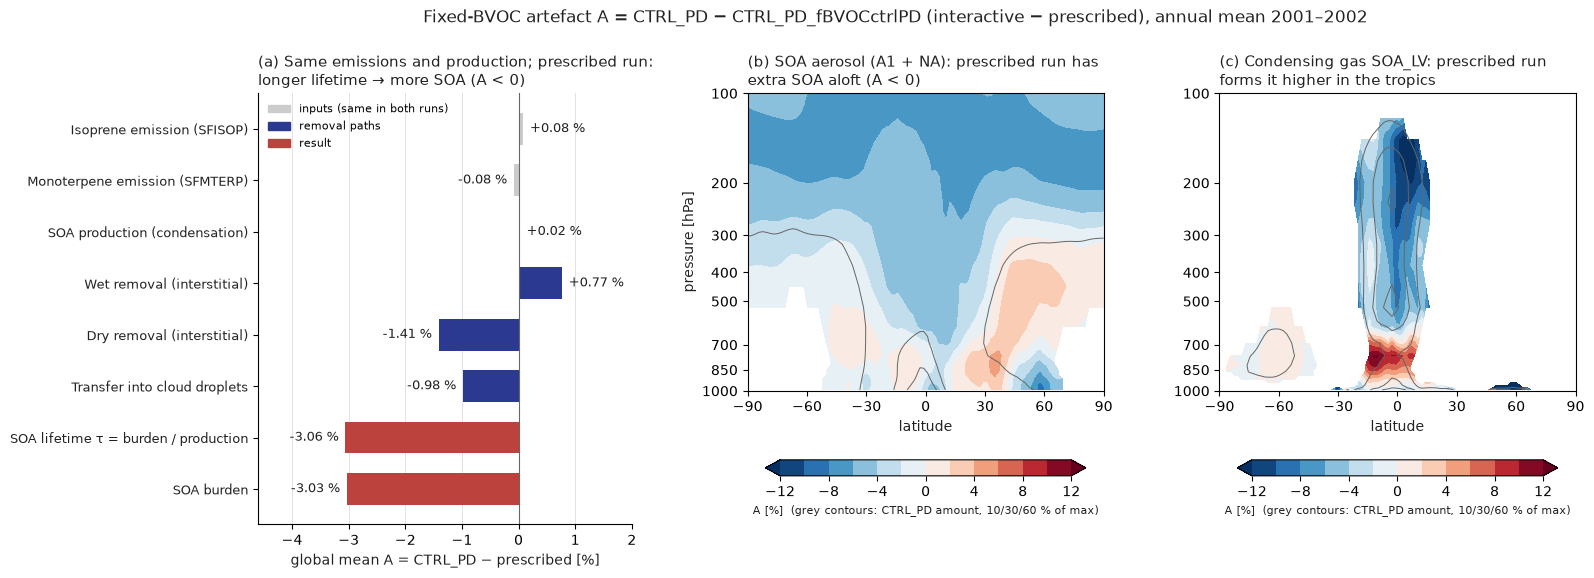

In [24]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
def zonal_section(ds, field):
    # annual zonal mean (lev, lat), month-length weighted over 2001-2002
    return field.weighted(dpm).mean('time').mean('lon')

sec = {}
for k in ('ctrl', 'art'):
    s_ = soa[k]
    sec[k] = {'aer': zonal_section(s_, s_['SOA_A1'] + s_['SOA_NA']), 'LV': zonal_section(s_, s_['SOA_LV'])}
lev = soa['ctrl']['lev'].values

# A = interactive − prescribed, % of CTRL_PD (user 2026-11-07)
bars = [('Isoprene emission (SFISOP)', 100 * (1 - gmean(bv['art'], 'SFISOP') / gmean(bv['ctrl'], 'SFISOP')), 'input'),
        ('Monoterpene emission (SFMTERP)', 100 * (1 - gmean(bv['art'], 'SFMTERP') / gmean(bv['ctrl'], 'SFMTERP')), 'input'),
        ('SOA production (condensation)', t4a.loc['A [%]', 'P [1e-12 kg m-2 s-1]'], 'input'),
        ('Wet removal (interstitial)', t4a.loc['A [%]', 'wet [1e-12 kg m-2 s-1]'], 'removal'),
        ('Dry removal (interstitial)', t4a.loc['A [%]', 'dry [1e-12 kg m-2 s-1]'], 'removal'),
        ('Transfer into cloud droplets', t4a.loc['A [%]', 'cloud [1e-12 kg m-2 s-1]'], 'removal'),
        ('SOA lifetime τ = burden / production', t4a.loc['A [%]', 'tau_P [days]'], 'result'),
        ('SOA burden', t4a.loc['A [%]', 'SOA_cb [mg m-2]'], 'result')]
COL = {'input': '#CCCCCC', 'removal': '#2C3990', 'result': '#BC423E'}
INK, MUTED = '#222222', '#666666'

fig = plt.figure(figsize=(17, 5.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.05, 1, 1], wspace=0.32)
ax = fig.add_subplot(gs[0])
y = np.arange(len(bars))[::-1]
for yi, (lab, val, grp) in zip(y, bars):
    ax.barh(yi, val, color=COL[grp], height=0.62)
    ax.text(val + (0.12 if val >= 0 else -0.12), yi, f'{val:+.2f} %', va='center', ha='left' if val >= 0 else 'right',
            fontsize=9, color=INK)
ax.set_yticks(y, [b[0] for b in bars], fontsize=9, color=INK)
ax.axvline(0, color=MUTED, lw=0.8); ax.set_xlim(-4.6, 2); ax.set_xticks(np.arange(-4, 3, 1))
ax.set_xlabel('global mean A = CTRL_PD − prescribed [%]', color=INK)
ax.grid(axis='x', color='#DDDDDD', lw=0.6); ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COL['input'], label='inputs (same in both runs)'),
                   Patch(color=COL['removal'], label='removal paths'),
                   Patch(color=COL['result'], label='result')], fontsize=8, loc='upper left', frameon=False)
ax.set_title('(a) Same emissions and production; prescribed run:\nlonger lifetime → more SOA (A < 0)', fontsize=11, color=INK, loc='left')

levels = np.arange(-12, 12.1, 2)
for i, (key, title, floor) in enumerate([('aer', '(b) SOA aerosol (A1 + NA): prescribed run has\nextra SOA aloft (A < 0)', 0.02),
                                        ('LV', '(c) Condensing gas SOA_LV: prescribed run\nforms it higher in the tropics', 0.05)]):
    ax = fig.add_subplot(gs[i + 1])
    c, a = sec['ctrl'][key], sec['art'][key]
    pct = (100 * (1 - a / c)).where(c > floor * float(c.max()))   # A = interactive − prescribed
    cf = ax.contourf(LAT, lev, pct.values, levels=levels, cmap='RdBu_r', extend='both')
    ax.contour(LAT, lev, c.values / float(c.max()), levels=[0.1, 0.3, 0.6], colors=MUTED, linewidths=0.7)
    ax.set_ylim(1000, 100); ax.set_yscale('log'); ax.set_yticks([1000, 850, 700, 500, 400, 300, 200, 100])
    ax.set_yticklabels([1000, 850, 700, 500, 400, 300, 200, 100]); ax.minorticks_off()
    ax.set_xticks(range(-90, 91, 30)); ax.set_xlabel('latitude', color=INK)
    if i == 0:
        ax.set_ylabel('pressure [hPa]', color=INK)
    ax.set_title(title, fontsize=11, color=INK, loc='left')
    cb = fig.colorbar(cf, ax=ax, orientation='horizontal', pad=0.16, shrink=0.9, ticks=levels[::2])
    cb.set_label('A [%]  (grey contours: CTRL_PD amount, 10/30/60 % of max)', fontsize=8, color=INK)
fig.suptitle('Fixed-BVOC artefact A = CTRL_PD − CTRL_PD_fBVOCctrlPD (interactive − prescribed), annual mean 2001–2002', fontsize=12, color=INK, y=1.03)
fig.savefig(OUT / 'figures' / 'synthesis_artefact_mechanism.png', dpi=170, bbox_inches='tight'); plt.show()

### Figure caption (draft, paper style)
**Figure X. Prescribing a biogenic-emission climatology lengthens the SOA lifetime by shifting SOA formation upward.** Differences between the nudged NorESM2 run with all 19 MEGAN-fed species prescribed from a 2001–2014 half-hourly climatology of CTRL_PD's own emissions (`CTRL_PD_fBVOCctrlPD`) and the run with interactive MEGAN emissions (`CTRL_PD`). The two runs share land cover, initial state, nudging and every other namelist setting, and the coupler exchanges the same fields apart from the 19 MEGAN fluxes. Annual means over 2001–2002 (the first model year, 2000, is discarded as spin-up), computed from monthly-mean output and weighted by month length. All panels show interactive minus prescribed in % of CTRL_PD, so negative values mean more in the prescribed run.
**(a)** Global-mean relative change of the emitted isoprene and monoterpene fluxes (total surface flux received by the atmosphere), of the interstitial SOA budget terms (modes A1 + NA) and of the SOA burden. Production is the condensation of the SOA precursor gases onto particles. Removal is split into wet deposition, dry deposition (gravitational + turbulent) and net transfer into cloud droplets (activation minus resuspension). Lifetime τ = burden / production. Global means are area-weighted (cos latitude). In both runs the budget closes to within 0.2 % of production. The burden is the column integral of the interstitial SOA mass mixing ratio (Σ q Δp / g, from monthly means). In the fixed-emission run it agrees with the model's own column diagnostic to within 0.01 mg m⁻² (2.511 vs 2.511 mg m⁻²).
**(b)** Zonal-mean relative change of the SOA aerosol mass mixing ratio (A1 + NA) and **(c)** of the low-volatility SOA precursor gas (`SOA_LV`), which condenses onto particles, so its distribution marks where SOA forms. Model levels are shown at their nominal pressure. Values are masked where the CTRL_PD amount is below 2 % (b) or 5 % (c) of its maximum. Grey contours show the CTRL_PD amount (10, 30, 60 % of the maximum).
Emissions and SOA production are unchanged (|Δ| ≤ 0.1 %), yet the burden rises by 3.0 % because SOA lives 3.1 % longer (7.02 → 7.24 days). The extra SOA is found at 400–100 hPa at all latitudes (+4.6 to +5.8 % per latitude band). In the tropics the condensing gas decreases at 850–700 hPa and increases at 500–150 hPa. **How the cause was narrowed down:**
- Missing species was ruled out by comparing the namelists, the CAM code path and the annual totals of all 19 species (within 0.5 %).
- A time-stamp offset was ruled out by comparing the diurnal cycles and lag correlations of the 30-min output with the prescribed files.
- Day-to-day emission variability correlates with the precursor lifetime change (Spearman ρ = 0.59) but not with the SOA change.

**Caveats:** two years only and no significance test, because the year-to-year variability of the difference is not yet characterised; cloud-borne SOA is not included (absent from the CTRL_PD output; in the fixed-emission run it holds 1 % of the burden but 22 % of the removal). That the upward shift comes from precursors being emitted on convective days and lifted before oxidation is a hypothesis, which the replay run `CTRL_PD_fBVOCctrlPD_HR` (actual emissions of each year prescribed) is designed to test.

### What exactly the figure shows: variables and calculations
**Input data (all panels).** Postprocessed monthly files `data/processed-data/postprocessing/<alias>_atm_{SOA,BVOC}_*.nc`. These are the CAM h0 monthly means, with the first 12 months (2000) dropped by the pipeline. Months used: the 24 months of 2001–2002, from `CTRL_PD` (case `-20261023`) and `CTRL_PD_fBVOCctrlPD` (case `-20261028`). Grid: 96 × 144 (1.9° × 2.5°), 32 hybrid levels, noleap calendar.

**Common steps**

| Step | Formula | Note |
|---|---|---|
| Time mean | X̄ = Σₘ dₘ Xₘ / Σₘ dₘ over the 24 months | dₘ = days in month m (31, 28, …) |
| Global mean (panel a) | G = Σⱼ Σᵢ cos φⱼ X̄ᵢⱼ / Σⱼ Σᵢ cos φⱼ | cos(latitude) = area weight on a regular lon–lat grid; every cell (land and ocean) included |
| Zonal mean (panels b, c) | Z(lev, φ) = (1/144) Σᵢ X̄ᵢ(lev, φ) | plain mean over longitudes (equal spacing) |
| A (% change) | 100 × (1 − value_fBVOC / value_CTRL) | interactive − prescribed in % of CTRL_PD (user 2026-11-07); **ratio of the means**, not mean of the cell ratios |

**Panel (a): global-mean % change of each quantity**

| Bar | Model field(s) (units) | What it is | CTRL_PD → fBVOC (global mean) | A |
|---|---|---|---|---|
| Isoprene emission | `SFISOP` (kg m⁻² s⁻¹) | total surface flux the atmosphere received (CTRL: MEGAN + biomass burning; fBVOC: the prescribed file) | 3.214 → 3.211 ×10⁻¹¹ | +0.08 % |
| Monoterpene emission | `SFMTERP` (kg m⁻² s⁻¹) | same, monoterpenes | 9.102 → 9.110 ×10⁻¹² | −0.08 % |
| SOA production P | `SOA_A1condTend + SOA_NAcondTend` (kg m⁻² s⁻¹, column) | condensation of the SOA gases (`SOA_LV`, `SOA_SV`) onto particles of modes A1 and NA | 4.017 → 4.016 ×10⁻¹² | +0.02 % |
| Wet removal | `SOA_A1SFWET + SOA_NASFWET` (kg m⁻² s⁻¹, negative = loss) | wet deposition of interstitial SOA at the surface | −2.510 → −2.491 ×10⁻¹² | +0.77 % (less removed in the prescribed run) |
| Dry removal | `SOA_A1DDF + SOA_NADDF` (kg m⁻² s⁻¹, positive = loss) | dry deposition, gravitational + turbulent | 0.615 → 0.623 ×10⁻¹² | −1.41 % |
| Transfer into droplets | `SOA_A1_mixnuc1 + SOA_NA_mixnuc1` (kg m⁻² s⁻¹, negative = loss) | net column tendency from droplet activation − resuspension (`dropmixnuc`): interstitial SOA that becomes cloud-borne | −0.884 → −0.893 ×10⁻¹² | −0.98 % (more transferred in the prescribed run) |
| SOA burden | `SOA_cb` (kg m⁻²) | Σₖ (q_A1 + q_NA)ₖ Δpₖ / g, with q the monthly-mean SOA mass mixing ratio (kg/kg) and Δpₖ = (A_{k+½} − A_{k−½}) P₀ + (B_{k+½} − B_{k−½}) PS from the monthly-mean surface pressure; computed offline in the postprocessing (`derived.soa_columns`) | 2.438 → 2.511 mg m⁻² | −3.03 % |
| SOA lifetime τ | G(`SOA_cb`) / G(P) | global burden divided by global production (from the two global means, not per cell) | 7.02 → 7.24 days | −3.06 % |

- **Worked example (τ, CTRL_PD):** 2.438 ×10⁻⁶ kg m⁻² / 4.017 ×10⁻¹² kg m⁻² s⁻¹ = 6.07 ×10⁵ s = **7.02 days**.
- **Budget check:** P + coagulation + droplet transfer + wet − dry = 4.017 + 0 − 0.884 − 2.510 − 0.615 = 0.008 ×10⁻¹² kg m⁻² s⁻¹ = **0.2 % of P** (CTRL_PD). The budget is closed, so production equals removal and τ = burden / production is also burden / removal.
- **Reading the signs:** wet removal is a negative flux. Its A = +0.77 % means a slightly *smaller* amount is washed out in the prescribed run, although it has 3 % more SOA. Removal per unit burden has dropped.

**Panel (b): SOA aerosol, zonal mean, % change**
- Field: q_aer = `SOA_A1` + `SOA_NA` (kg/kg), the interstitial SOA mass mixing ratio on each model level.
- Calculation: time mean → zonal mean Z(lev, φ) in each run → A = 100 × (1 − Z_fBVOC / Z_CTRL) per (level, latitude).
- **Worked example:** level 233 hPa, 0.9°S: Z_CTRL = 3.759 ×10⁻¹⁰, Z_fBVOC = 3.963 ×10⁻¹⁰ kg/kg → **A = −5.4 %**.
- Mask: white where Z_CTRL < 2 % of the maximum of the CTRL section, so tiny amounts do not give large %.
- Grey contours: Z_CTRL / max(Z_CTRL) = 0.1, 0.3 and 0.6, showing where the SOA actually is.
- Vertical axis: the model's `lev` coordinate, 1000 × (A + B) hPa = the level's pressure for a surface pressure of 1000 hPa. It is a nominal pressure. Over high terrain the real pressure of a level is lower, and near the surface the levels follow the terrain.

**Panel (c): condensing gas `SOA_LV`, zonal mean, % change**
- Field: `SOA_LV` (mol/mol), the low-volatility SOA gas formed from monoterpene + O₃ (yield 0.15 in the mechanism). In the OsloAero code a fraction `lvocfrac` = 0.5 of it is available for nucleation (session log, code reading); the rest condenses onto particles. Where `SOA_LV` is high is where SOA is made. Its 3-D production rate is not in the output, so `SOA_LV` is the proxy.
- Same calculation as (b). Mask: 5 % of the CTRL maximum, because SOA_LV falls off steeply away from the sources.
- **Worked example:** 233 hPa, 0.9°S: 3.836 ×10⁻¹³ → 4.225 ×10⁻¹³ mol/mol → **A = −10.1 %**.
- Colour scale (b, c): steps of 2 %, from −12 to +12 %; values beyond are shown in the end colours.

**What is not in the figure**
- Cloud-borne SOA (`SOA_*_OCW`): not in the CTRL_PD output (old chain), so neither its burden nor its removal is included. In the fBVOC run it is 1 % of the burden and 22 % of the removal (H4e).
- No significance test: with 2 years the year-to-year spread of the difference is not known; for reference, the 14-year contrast `LCC_PD_fBVOCctrlPD − CTRL_PD` had a year-to-year SD of 0.8 % in the global SOA burden (artefact notebook).
- The 3-D distribution of production is inferred from `SOA_LV`, not computed.